# Model 1 — Standard Two-Stage Composite SupCon

Trains the Member 1 model and reports generalized zero-shot results on DPD-Small.

The backbone is ImageNet **ViT-B/16**. Stage 1 trains one projection head with supervised contrastive loss on composition ids (`0..332`). Stage 2 discards that head, freezes the backbone, and trains a crop head (55 classes) and a disease head (175 classes). A composition is scored as

`crop_logit[crop] + disease_logit[disease] - bias`

with the bias subtracted from seen pairs only.

The dev split holds out 15 training compositions (`seed=42`), sweeps bias from -12 to 24, and keeps the stage-2 epoch and bias with the best harmonic mean. The final run retrains on all 8,000 training images for that epoch count, then evaluates **test-seen** and **test-unseen**.

`model1_results/best.pt` stores `model`, `epoch`, and `dev_bias`. The state dict has the same `backbone`, `crop_head`, and `disease_head` keys as Baseline 2, so `evaluate_baselines_2.ipynb` can load it.

**Use a GPU.** A full run is two ViT-B/16 trainings (dev selection, then the final model).

**Colab.** Upload this project folder (this notebook and `DPD_Small`, about 3 GB) to Google Drive. In Colab choose Runtime → Change runtime type → T4 GPU, then run all cells. The setup cell mounts Drive, copies the images onto the Colab disk, and writes `model1_results` back to the same Drive folder. If the folder is not found, set `COLAB_DPD_ROOT` in that cell to the Drive path that contains `DPD_Small`.

**Local.** Run from the project folder on a GPU.


## 0. Colab setup

On Colab this cell mounts Google Drive, finds the folder that contains `DPD_Small`, and copies the images to the Colab disk. Checkpoints and figures are written back to `model1_results` on Drive.

Leave `COLAB_DPD_ROOT` empty unless the search does not find the dataset. It must be the folder that contains `DPD_Small`, for example `/content/drive/MyDrive/deep_learning`.

A local run skips this cell's Drive steps.

In [1]:
import os
from pathlib import Path

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Leave empty to use the My Drive shortcut named deep_learning.
# Set this only if the shortcut has another path.
COLAB_DPD_ROOT = ""


def list_names(path: Path) -> list[str]:
    try:
        return sorted(os.listdir(path))
    except OSError:
        return []


def has_dpd(root: Path) -> bool:
    csv_path = root / "DPD_Small" / "DPD_Small_train.csv"
    if "DPD_Small_train.csv" in list_names(root / "DPD_Small"):
        return True
    try:
        return csv_path.is_file()
    except OSError:
        return False


def find_project_root() -> Path | None:
    """Find the folder that contains DPD_Small, including Drive shortcuts.

    Shortcuts often fail Path.is_dir(), so this lists names and tries to open them.
    A folder that also contains model1_results/last.pt wins, so a loose DPD_Small
    copy is not used in place of the shared project.
    """
    starts = []
    if COLAB_DPD_ROOT:
        starts.append(Path(COLAB_DPD_ROOT))
    starts.extend(
        [
            Path("/content/drive/MyDrive"),
            Path("/content/drive/Shareddrives"),
            Path("/content/drive/.shortcut-targets-by-id"),
        ]
    )
    seen = set()
    found = []
    queue = [(path, 0) for path in starts]
    while queue:
        current, depth = queue.pop(0)
        key = str(current)
        if key in seen or depth > 4:
            continue
        seen.add(key)
        if has_dpd(current):
            found.append(current)
        names = list_names(current)
        if depth == 4:
            continue
        for name in names:
            if name.startswith(".") and current.name != ".shortcut-targets-by-id":
                continue
            if name in {"DPD_Small_dataset", "model1_results", "__pycache__"}:
                continue
            queue.append((current / name, depth + 1))
    if not found:
        return None
    def rank(path: Path) -> tuple:
        ready = "last.pt" in list_names(path / "model1_results")
        return (0 if ready else 1, len(path.parts))
    return sorted(found, key=rank)[0]


if not IN_COLAB:
    print("Local session. The configuration cell uses the project folder next to this notebook.")
else:
    from google.colab import drive

    drive.mount("/content/drive")
    source = find_project_root()
    if source is None:
        visible = list_names(Path("/content/drive/MyDrive"))
        preview = ", ".join(visible[:30]) or "(empty)"
        raise FileNotFoundError(
            "Could not find DPD_Small under My Drive, shared drives, or Drive shortcuts. "
            "Shared with me is not mounted until you add a shortcut: Drive → Shared with me → "
            "right-click deep_learning → Organize → Add shortcut to Drive → My Drive. "
            f"Folders visible in My Drive: {preview}"
        )

    results = source / "model1_results"
    results.mkdir(parents=True, exist_ok=True)
    probe = results / ".write_probe"
    try:
        probe.write_text("ok", encoding="utf-8")
        probe.unlink()
    except OSError as exc:
        raise PermissionError(
            f"{results} is not writable. Share deep_learning with this account as Editor."
        ) from exc

    os.environ["DPD_ROOT"] = str(source)
    os.environ["DPD_OUTPUT"] = str(results)
    os.environ["DPD_NUM_WORKERS"] = "0"
    print(f"Dataset: {source / 'DPD_Small'}")
    print(f"Results: {results}")

    import torch

    if torch.cuda.is_available():
        props = torch.cuda.get_device_properties(0)
        gb = props.total_memory / (1024 ** 3)
        os.environ["COLAB_GPU_GB"] = f"{gb:.2f}"
        print(f"GPU: {torch.cuda.get_device_name(0)} ({gb:.1f} GB)")
        if gb <= 16.5:
            print("16 GB GPU: stage 1 uses batch 16 and 4 accumulation steps (same 64-image update).")
    else:
        print("No GPU is attached. Use Runtime → Change runtime type → T4 GPU, then rerun this cell.")


Mounted at /content/drive
Dataset: /content/drive/MyDrive/deep_learning/DPD_Small
Results: /content/drive/MyDrive/deep_learning/model1_results
GPU: Tesla T4 (14.6 GB)
16 GB GPU: stage 1 uses batch 16 and 4 accumulation steps (same 64-image update).


## 1. Imports and constants

In [ ]:
import json
import math
import os
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image, ImageEnhance
from sklearn.metrics import auc, silhouette_score
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader, Dataset

try:
    from tqdm.auto import tqdm
except ImportError:  # pragma: no cover
    def tqdm(iterable, **kwargs):
        return iterable

try:
    BICUBIC = Image.Resampling.BICUBIC
except AttributeError:  # pragma: no cover
    BICUBIC = Image.BICUBIC

# ImageNet-1k ViT-B/16 weights used by timm's vit_base_patch16_224. Loaded with
# torch.hub so training does not import torchvision (its native module is blocked
# on some Windows installs, and timm imports torchvision).
VIT_B16_URL = (
    "https://github.com/huggingface/pytorch-image-models/releases/download/"
    "v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth"
)


IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD = (0.229, 0.224, 0.225)
NUM_CROPS = 55
NUM_DISEASES = 175
EMBED_DIM = 768

# Numbers from the team's Baseline 2 run (final/metrics.json). Used only when
# that file is not on disk.
BASELINE2_FALLBACK = {
    "model": "Baseline 2: multi-task ResNet-50",
    "auc": 0.5409409495142012,
    "dev_bias": 4.994729042053223,
    "results": {
        "b = 0 (no calibration)": {
            "bias": 0.0,
            "seen top-1": 0.7139999866485596,
            "seen top-5": 0.9169999957084656,
            "unseen top-1": 0.05248618870973587,
            "unseen top-5": 0.31491711735725403,
            "harmonic mean": 0.09778425036946652,
        },
        "b from dev validation (REPORTED)": {
            "bias": 4.995,
            "seen top-1": 0.6639999747276306,
            "seen top-5": 0.8989999890327454,
            "unseen top-1": 0.5158839821815491,
            "unseen top-5": 0.9364640712738037,
            "harmonic mean": 0.5806451543391995,
        },
        "oracle b on test (upper bound)": {
            "bias": 6.27,
            "seen top-1": 0.5920000076293945,
            "seen top-5": 0.8769999742507935,
            "unseen top-1": 0.6933701634407043,
            "unseen top-5": 0.966160237789154,
            "harmonic mean": 0.6386878290557527,
        },
    },
    "paper_protocol_hm": 0.05443574924489129,
    "shortcut_rate": 0.6831683168316832,
    "heads": {
        "test-seen": {
            "crop acc": 0.9325000047683716,
            "disease acc": 0.7260000109672546,
            "crop+disease acc": 0.7024999856948853,
        },
        "test-unseen": {
            "crop acc": 0.7762430906295776,
            "disease acc": 0.09323204308748245,
            "crop+disease acc": 0.028314916417002678,
        },
    },
}


## 2. Paths and CSV loading

In [ ]:
def default_config() -> dict:
    return {
        "seed": 42,
        "stage1_epochs": 15,
        "stage2_max_epochs": 12,
        "batch_size": 32,
        "accum_steps": 2,
        "stage2_batch_size": 64,
        "eval_batch_size": 64,
        "num_workers": 0 if os.name == "nt" else 2,
        "temperature": 0.07,
        "stage1_lr_backbone": 3e-5,
        "stage1_lr_projector": 3e-4,
        "stage1_weight_decay": 1e-4,
        "stage2_lr": 1e-3,
        "stage2_weight_decay": 1e-4,
        "num_holdout_pairs": 15,
        "val_frac": 0.1,
        "bias_min": -12.0,
        "bias_max": 24.0,
        "bias_step": 0.25,
        "pretrained": True,
        "allow_cpu_full_train": False,
        "limit_train_rows": None,
        "limit_test_rows": None,
        "root": None,
        "output_dir": None,
    }


def set_seed(seed: int) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


def find_project_root(start: str | Path | None = None) -> Path:
    env = os.environ.get("DPD_ROOT")
    if start is None and env:
        start = env
    start_path = Path(start or Path.cwd()).resolve()
    for cand in [start_path, *start_path.parents]:
        if (cand / "DPD_Small" / "DPD_Small_train.csv").exists():
            return cand
    raise FileNotFoundError(
        "Could not find DPD_Small/DPD_Small_train.csv. "
        "Run from the project folder or set DPD_ROOT."
    )


def resolve_config(cfg: dict | None) -> dict:
    merged = default_config()
    if cfg:
        merged.update(cfg)
    if int(merged["stage1_epochs"]) < 1 or int(merged["stage2_max_epochs"]) < 1:
        raise ValueError("stage1_epochs and stage2_max_epochs must be at least 1")
    root = find_project_root(merged.get("root"))
    merged["root"] = str(root)
    out = merged.get("output_dir") or (root / "model1_results")
    merged["output_dir"] = str(Path(out))
    Path(merged["output_dir"]).mkdir(parents=True, exist_ok=True)
    return merged


def load_split(path: Path) -> pd.DataFrame:
    df = pd.read_csv(path, header=None)
    if df.shape[1] < 7:
        raise ValueError(f"{path} should have 7 columns, found {df.shape[1]}")
    df = df.iloc[:, :7].copy()
    df.columns = ["file", "crop", "disease", "comp", "crop_name", "disease_name", "comp_name"]
    df["crop"] = df["crop"].astype(int)
    df["disease"] = df["disease"].astype(int)
    df["comp"] = df["comp"].astype(int)
    return df.reset_index(drop=True)


def limit_rows(df: pd.DataFrame, n: int | None, seed: int) -> pd.DataFrame:
    if n is None or n >= len(df):
        return df.reset_index(drop=True)
    return df.sample(n=n, random_state=seed).reset_index(drop=True)


def check_images(df: pd.DataFrame, img_dir: Path) -> None:
    on_disk = set(os.listdir(img_dir))
    missing = sorted(set(df["file"].astype(str)) - on_disk)
    if missing:
        preview = ", ".join(missing[:5])
        raise FileNotFoundError(
            f"{len(missing)} images listed in the CSVs are missing from {img_dir}. "
            f"Examples: {preview}"
        )


## 3. Augmentations and the dataset

In [ ]:
class Compose:
    def __init__(self, ops):
        self.ops = ops

    def __call__(self, image):
        for op in self.ops:
            image = op(image)
        return image


class RandomResizedCrop:
    def __init__(self, size, scale=(0.6, 1.0), ratio=(0.75, 4.0 / 3.0)):
        self.size = size
        self.scale = scale
        self.ratio = ratio

    def __call__(self, image):
        i, j, h, w = self._params(image)
        cropped = image.crop((j, i, j + w, i + h))
        return cropped.resize((self.size, self.size), BICUBIC)

    def _params(self, image):
        width, height = image.size
        area = height * width
        log_ratio = (math.log(self.ratio[0]), math.log(self.ratio[1]))
        for _ in range(10):
            target = area * random.uniform(*self.scale)
            aspect = math.exp(random.uniform(*log_ratio))
            w = int(round(math.sqrt(target * aspect)))
            h = int(round(math.sqrt(target / aspect)))
            if 0 < w <= width and 0 < h <= height:
                top = random.randint(0, height - h)
                left = random.randint(0, width - w)
                return top, left, h, w
        return 0, 0, height, width


class RandomHorizontalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, image):
        if random.random() < self.p:
            return image.transpose(Image.FLIP_LEFT_RIGHT)
        return image


class RandomVerticalFlip:
    def __init__(self, p=0.5):
        self.p = p

    def __call__(self, image):
        if random.random() < self.p:
            return image.transpose(Image.FLIP_TOP_BOTTOM)
        return image


class RandomRotation:
    def __init__(self, degrees):
        self.degrees = degrees

    def __call__(self, image):
        angle = random.uniform(-self.degrees, self.degrees)
        return image.rotate(angle, resample=BICUBIC, expand=False, fillcolor=(0, 0, 0))


def _adjust_hue(image, factor):
    if factor == 0:
        return image
    hsv = np.array(image.convert("HSV"), dtype=np.int16)
    hsv[:, :, 0] = (hsv[:, :, 0] + int(round(factor * 255.0))) % 256
    return Image.fromarray(hsv.astype(np.uint8), mode="HSV").convert("RGB")


class ColorJitter:
    """Mild jitter. Order is shuffled so disease colour is not pushed one way."""

    def __init__(self, brightness=0.0, contrast=0.0, saturation=0.0, hue=0.0):
        self.brightness = brightness
        self.contrast = contrast
        self.saturation = saturation
        self.hue = hue

    def __call__(self, image):
        ops = []
        if self.brightness:
            ops.append(("b", random.uniform(1 - self.brightness, 1 + self.brightness)))
        if self.contrast:
            ops.append(("c", random.uniform(1 - self.contrast, 1 + self.contrast)))
        if self.saturation:
            ops.append(("s", random.uniform(1 - self.saturation, 1 + self.saturation)))
        if self.hue:
            ops.append(("h", random.uniform(-self.hue, self.hue)))
        random.shuffle(ops)
        for kind, factor in ops:
            if kind == "b":
                image = ImageEnhance.Brightness(image).enhance(factor)
            elif kind == "c":
                image = ImageEnhance.Contrast(image).enhance(factor)
            elif kind == "s":
                image = ImageEnhance.Color(image).enhance(factor)
            else:
                image = _adjust_hue(image, factor)
        return image


class Resize:
    def __init__(self, size):
        self.size = size if isinstance(size, tuple) else (size, size)

    def __call__(self, image):
        return image.resize(self.size, BICUBIC)


class ToTensor:
    def __call__(self, image):
        array = np.asarray(image.convert("RGB"), dtype=np.float32) / 255.0
        return torch.from_numpy(array).permute(2, 0, 1).contiguous()


class Normalize:
    def __init__(self, mean, std):
        self.mean = mean
        self.std = std

    def __call__(self, tensor):
        mean = torch.tensor(self.mean, dtype=tensor.dtype).view(3, 1, 1)
        std = torch.tensor(self.std, dtype=tensor.dtype).view(3, 1, 1)
        return (tensor - mean) / std


def symptom_preserving_train_transform() -> Compose:
    # Blueprint stage 0: mild colour jitter so chlorosis, rust, and necrosis stay intact.
    return Compose(
        [
            RandomResizedCrop(224, scale=(0.6, 1.0)),
            RandomHorizontalFlip(),
            RandomVerticalFlip(),
            RandomRotation(20),
            ColorJitter(brightness=0.15, contrast=0.15, saturation=0.1, hue=0.02),
            ToTensor(),
            Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]
    )


def eval_transform() -> Compose:
    return Compose(
        [
            Resize((224, 224)),
            ToTensor(),
            Normalize(IMAGENET_MEAN, IMAGENET_STD),
        ]
    )


class TwoCropTransform:
    """Two independent stochastic views of the same image."""

    def __init__(self, base):
        self.base = base

    def __call__(self, image):
        return self.base(image), self.base(image)


class DPDSplit(Dataset):
    def __init__(self, frame: pd.DataFrame, img_dir: Path, transform, two_view: bool):
        self.df = frame.reset_index(drop=True)
        self.img_dir = Path(img_dir)
        self.transform = transform
        self.two_view = two_view

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx: int):
        row = self.df.iloc[idx]
        path = self.img_dir / str(row["file"])
        with Image.open(path) as im:
            image = im.convert("RGB")
            image.load()
        sample = {
            "crop": int(row["crop"]),
            "disease": int(row["disease"]),
            "comp": int(row["comp"]),
            "file": str(row["file"]),
        }
        if self.two_view:
            view1, view2 = self.transform(image)
            sample["view1"] = view1
            sample["view2"] = view2
        else:
            sample["image"] = self.transform(image)
        return sample


def make_loader(frame, img_dir, transform, two_view, batch_size, shuffle, num_workers, seed, pin):
    dataset = DPDSplit(frame, img_dir, transform, two_view=two_view)
    generator = torch.Generator()
    generator.manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=shuffle,
        num_workers=num_workers,
        pin_memory=pin,
        generator=generator if shuffle else None,
    )


## 4. Dev split and composition label space

In [ ]:
class CompositionSpace:
    """Closed set of crop-disease compositions and the seen-pair mask."""

    def __init__(self, frames: list[pd.DataFrame], seen_comp_ids: set[int]):
        rows = pd.concat(frames, ignore_index=True)
        grouped = (
            rows.groupby("comp", as_index=False)
            .agg(
                crop=("crop", "first"),
                disease=("disease", "first"),
                name=("comp_name", "first"),
                crop_name=("crop_name", "first"),
                disease_name=("disease_name", "first"),
            )
            .sort_values("comp")
            .reset_index(drop=True)
        )
        self.frame = grouped
        self.comp_ids = grouped["comp"].to_numpy(dtype=np.int64)
        self.crop_of = torch.tensor(grouped["crop"].to_numpy(dtype=np.int64), dtype=torch.long)
        self.disease_of = torch.tensor(grouped["disease"].to_numpy(dtype=np.int64), dtype=torch.long)
        names = []
        used = {}
        for comp_id, name in zip(self.comp_ids.tolist(), grouped["name"].astype(str).tolist()):
            if name in used:
                name = f"{name}__{comp_id}"
            used[name] = comp_id
            names.append(name)
        self.names = names
        self.id_to_index = {int(c): i for i, c in enumerate(self.comp_ids.tolist())}
        self.seen_mask = torch.tensor(
            [int(c) in seen_comp_ids for c in self.comp_ids.tolist()], dtype=torch.bool
        )
        self.seen_comp_ids = {int(c) for c in seen_comp_ids}

    def targets(self, comp_ids: np.ndarray) -> torch.Tensor:
        try:
            idx = [self.id_to_index[int(c)] for c in comp_ids.tolist()]
        except KeyError as exc:
            raise KeyError(f"Composition {exc} is outside this label space") from exc
        return torch.tensor(idx, dtype=torch.long)


def dev_split(train_df: pd.DataFrame, num_holdout: int, val_frac: float, seed: int):
    """Hold out composition pairs, then take a stratified image slice as dev-seen."""
    comp_ids = np.sort(train_df["comp"].unique())
    if num_holdout >= len(comp_ids):
        raise ValueError(
            f"Holdout pairs ({num_holdout}) must be smaller than the number of "
            f"training compositions ({len(comp_ids)})."
        )
    rng = np.random.default_rng(seed)
    holdout = np.sort(rng.choice(comp_ids, size=num_holdout, replace=False))
    holdout_set = set(int(c) for c in holdout.tolist())
    holdout_df = train_df[train_df["comp"].isin(holdout_set)].reset_index(drop=True)
    rest = train_df[~train_df["comp"].isin(holdout_set)].reset_index(drop=True)

    train_parts = []
    val_parts = []
    for _, group in rest.groupby("comp", sort=True):
        group = group.sample(frac=1.0, random_state=seed)
        n_val = int(round(len(group) * val_frac))
        if n_val >= len(group):
            n_val = len(group) - 1
        n_val = max(0, n_val)
        val_parts.append(group.iloc[:n_val])
        train_parts.append(group.iloc[n_val:])
    dev_train = pd.concat(train_parts, ignore_index=True)
    kept_val = [part for part in val_parts if len(part)]
    dev_seen = pd.concat(kept_val, ignore_index=True) if kept_val else rest.iloc[:0].copy()
    if len(dev_seen) == 0:
        # Tiny subsets can be all singletons after rounding. Pull a few extra
        # images into dev-seen while leaving one training image of that pair.
        counts = rest.groupby("comp").size()
        eligible_ids = set(counts[counts > 1].index.tolist())
        eligible = rest[rest["comp"].isin(eligible_ids)]
        n_val = max(1, int(round(len(rest) * val_frac)))
        if len(eligible) == 0:
            raise RuntimeError(
                "Dev split has no seen-validation images. "
                "Lower num_holdout_pairs or raise limit_train_rows."
            )
        dev_seen = eligible.sample(n=min(n_val, len(eligible)), random_state=seed)
        dev_train = rest.drop(index=dev_seen.index).reset_index(drop=True)
        dev_seen = dev_seen.reset_index(drop=True)
    if len(dev_train) == 0 or len(dev_seen) == 0 or len(holdout_df) == 0:
        raise RuntimeError(
            "Dev split is empty. Lower num_holdout_pairs or raise limit_train_rows. "
            f"train={len(dev_train)} seen-val={len(dev_seen)} pseudo-unseen={len(holdout_df)}"
        )
    return dev_train.reset_index(drop=True), dev_seen.reset_index(drop=True), holdout_df, holdout_set


## 5. ViT-B/16 and composite SupCon loss

In [ ]:
class PatchEmbed(nn.Module):
    def __init__(self, img_size=224, patch_size=16, embed_dim=EMBED_DIM):
        super().__init__()
        self.proj = nn.Conv2d(3, embed_dim, kernel_size=patch_size, stride=patch_size)
        self.grid = img_size // patch_size

    def forward(self, images):
        patches = self.proj(images)
        return patches.flatten(2).transpose(1, 2)


class Attention(nn.Module):
    def __init__(self, dim=EMBED_DIM, num_heads=12):
        super().__init__()
        self.num_heads = num_heads
        self.scale = (dim // num_heads) ** -0.5
        self.qkv = nn.Linear(dim, dim * 3, bias=True)
        self.proj = nn.Linear(dim, dim, bias=True)

    def forward(self, tokens):
        batch, length, dim = tokens.shape
        qkv = self.qkv(tokens).reshape(batch, length, 3, self.num_heads, dim // self.num_heads)
        qkv = qkv.permute(2, 0, 3, 1, 4)
        query, key, value = qkv.unbind(0)
        scores = (query @ key.transpose(-2, -1)) * self.scale
        weights = scores.softmax(dim=-1)
        mixed = (weights @ value).transpose(1, 2).reshape(batch, length, dim)
        return self.proj(mixed)


class Mlp(nn.Module):
    def __init__(self, dim=EMBED_DIM, hidden=3072):
        super().__init__()
        self.fc1 = nn.Linear(dim, hidden)
        self.fc2 = nn.Linear(hidden, dim)

    def forward(self, tokens):
        return self.fc2(F.gelu(self.fc1(tokens)))


class Block(nn.Module):
    def __init__(self, dim=EMBED_DIM):
        super().__init__()
        self.norm1 = nn.LayerNorm(dim, eps=1e-6)
        self.attn = Attention(dim)
        self.norm2 = nn.LayerNorm(dim, eps=1e-6)
        self.mlp = Mlp(dim)

    def forward(self, tokens):
        tokens = tokens + self.attn(self.norm1(tokens))
        tokens = tokens + self.mlp(self.norm2(tokens))
        return tokens


class VisionTransformerB16(nn.Module):
    """ViT-B/16 with the same state-dict names as timm vit_base_patch16_224."""

    def __init__(self):
        super().__init__()
        self.patch_embed = PatchEmbed()
        self.cls_token = nn.Parameter(torch.zeros(1, 1, EMBED_DIM))
        self.pos_embed = nn.Parameter(torch.zeros(1, 197, EMBED_DIM))
        self.blocks = nn.ModuleList([Block() for _ in range(12)])
        self.norm = nn.LayerNorm(EMBED_DIM, eps=1e-6)
        self.apply(self._init_weights)

    @staticmethod
    def _init_weights(module):
        if isinstance(module, nn.Linear):
            nn.init.trunc_normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Conv2d):
            nn.init.trunc_normal_(module.weight, std=0.02)
            if module.bias is not None:
                nn.init.zeros_(module.bias)
        elif isinstance(module, nn.LayerNorm):
            nn.init.ones_(module.weight)
            nn.init.zeros_(module.bias)

    def forward(self, images):
        tokens = self.patch_embed(images)
        cls = self.cls_token.expand(tokens.shape[0], -1, -1)
        tokens = torch.cat((cls, tokens), dim=1) + self.pos_embed
        for block in self.blocks:
            tokens = block(tokens)
        tokens = self.norm(tokens)
        return tokens[:, 0]


def load_imagenet_vit(backbone: VisionTransformerB16) -> None:
    try:
        state = torch.hub.load_state_dict_from_url(VIT_B16_URL, map_location="cpu", progress=True)
    except Exception as exc:
        raise RuntimeError(
            "Could not download the ImageNet ViT-B/16 weights. Check the network and run again."
        ) from exc
    if isinstance(state, dict) and "state_dict" in state:
        state = state["state_dict"]
    cleaned = {}
    for key, value in state.items():
        key = key.replace("module.", "")
        if key.startswith("head.") or key.startswith("fc."):
            continue
        cleaned[key] = value
    missing, unexpected = backbone.load_state_dict(cleaned, strict=False)
    if missing or unexpected:
        raise RuntimeError(
            f"ViT weight mismatch. Missing {missing[:8]}, unexpected {unexpected[:8]}."
        )


class ProjectionHead(nn.Module):
    def __init__(self, in_dim: int = EMBED_DIM, hidden: int = 256, out_dim: int = 128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden),
            nn.LayerNorm(hidden),
            nn.GELU(),
            nn.Linear(hidden, out_dim),
        )

    def forward(self, features: torch.Tensor) -> torch.Tensor:
        projected = self.net(features)
        return F.normalize(projected.float(), dim=-1)


class CompositeSupConViT(nn.Module):
    """ViT-B/16 with one composite projection head and two linear classifiers."""

    def __init__(self, pretrained: bool = True):
        super().__init__()
        self.backbone = VisionTransformerB16()
        if pretrained:
            load_imagenet_vit(self.backbone)
        self.projector = ProjectionHead()
        self.crop_head = nn.Linear(EMBED_DIM, NUM_CROPS)
        self.disease_head = nn.Linear(EMBED_DIM, NUM_DISEASES)

    def forward_supcon(self, images: torch.Tensor) -> torch.Tensor:
        return self.projector(self.backbone(images))

    def forward_heads(self, images: torch.Tensor):
        features = self.backbone(images)
        return self.crop_head(features), self.disease_head(features)

    def reset_classifier_heads(self):
        device = next(self.backbone.parameters()).device
        self.crop_head = nn.Linear(EMBED_DIM, NUM_CROPS).to(device)
        self.disease_head = nn.Linear(EMBED_DIM, NUM_DISEASES).to(device)

    def freeze_backbone(self):
        for param in self.backbone.parameters():
            param.requires_grad = False
        self.backbone.eval()

    def export_eval_state_dict(self) -> dict:
        # evaluate_baselines_2.ipynb loads backbone + crop_head + disease_head only.
        return {
            key: value.detach().cpu()
            for key, value in self.state_dict().items()
            if not key.startswith("projector.")
        }


class SupConLoss(nn.Module):
    """Khosla et al. supervised contrastive loss over the 2N augmented views."""

    def __init__(self, temperature: float = 0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        if features.ndim != 2:
            raise ValueError("SupCon features must have shape [2N, D]")
        features = F.normalize(features.float(), dim=-1)
        labels = labels.view(-1, 1)
        batch = features.shape[0]
        logits = features @ features.T
        logits = logits / self.temperature
        logits = logits - logits.max(dim=1, keepdim=True).values.detach()

        positive = torch.eq(labels, labels.T).float()
        self_mask = torch.eye(batch, device=features.device)
        logits_mask = 1.0 - self_mask
        positive = positive * logits_mask

        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(dim=1, keepdim=True).clamp_min(1e-12))
        positive_count = positive.sum(dim=1)
        mean_log_prob = (positive * log_prob).sum(dim=1) / positive_count.clamp_min(1.0)
        valid = positive_count > 0
        if not torch.any(valid):
            return features.sum() * 0.0
        return -mean_log_prob[valid].mean()


## 6. Stage 1 and stage 2 training

In [ ]:
def warmup_cosine_lambda(warmup_steps: int, total_steps: int):
    warmup_steps = max(1, warmup_steps)
    total_steps = max(warmup_steps + 1, total_steps)

    def lr_lambda(step: int) -> float:
        if step < warmup_steps:
            return float(step + 1) / float(warmup_steps)
        progress = (step - warmup_steps) / float(total_steps - warmup_steps)
        progress = min(max(progress, 0.0), 1.0)
        return 0.5 * (1.0 + math.cos(math.pi * progress))

    return lr_lambda


class _NoScaler:
    """Stand-in for GradScaler when autocast is off (CPU pipeline checks)."""

    def scale(self, loss):
        return loss

    def step(self, optimizer):
        optimizer.step()

    def update(self):
        return None


def make_scaler(enabled: bool):
    if not enabled:
        return _NoScaler()
    # torch.amp.GradScaler("cuda") is the current API. Older Colab
    # torch builds only accept the enabled= keyword, or torch.cuda.amp.
    try:
        return torch.amp.GradScaler("cuda")
    except TypeError:
        try:
            return torch.amp.GradScaler(enabled=True)
        except (TypeError, AttributeError):
            return torch.cuda.amp.GradScaler()


def optimizer_steps_per_epoch(n_batches: int, accum_steps: int) -> int:
    if n_batches <= 0:
        return 1
    return int(math.ceil(n_batches / float(accum_steps)))


_EPOCH_BEST = {}


def reset_epoch_checkpoints() -> None:
    _EPOCH_BEST.clear()


def save_epoch_checkpoint(
    model,
    output_dir,
    tag: str,
    stage: str,
    epoch: int,
    score: float,
    higher_is_better: bool,
    score_name: str,
    dev_bias: float | None = None,
) -> None:
    """Overwrite last.pt every epoch. Overwrite best.pt when this epoch improves the stage."""
    if not output_dir:
        return
    out = Path(output_dir)
    out.mkdir(parents=True, exist_ok=True)
    payload = {
        "model": model.export_eval_state_dict(),
        "projector": {
            key: value.detach().cpu() for key, value in model.projector.state_dict().items()
        },
        "epoch": int(epoch),
        "stage": stage,
        "tag": tag,
        "score": float(score),
        "score_name": score_name,
        "dev_bias": None if dev_bias is None else float(dev_bias),
        "model_name": "Model 1: Standard Two-Stage Composite SupCon",
    }
    torch.save(payload, out / "last.pt")
    key = (tag, stage)
    previous = _EPOCH_BEST.get(key)
    improved = previous is None or (score > previous if higher_is_better else score < previous)
    if improved:
        _EPOCH_BEST[key] = float(score)
        torch.save(payload, out / "best.pt")
        torch.save(payload, out / f"best_{tag}_{stage}.pt")
    status_path = out / "checkpoint_status.json"
    status = {}
    if status_path.exists():
        try:
            status = json.loads(status_path.read_text(encoding="utf-8"))
        except json.JSONDecodeError:
            status = {}
    status["last"] = {
        "file": "last.pt",
        "tag": tag,
        "stage": stage,
        "epoch": int(epoch),
        "score_name": score_name,
        "score": float(score),
    }
    if improved:
        status["best"] = {
            "file": "best.pt",
            "kept_as": f"best_{tag}_{stage}.pt",
            "tag": tag,
            "stage": stage,
            "epoch": int(epoch),
            "score_name": score_name,
            "score": float(score),
        }
    status_path.write_text(json.dumps(status, indent=2), encoding="utf-8")
    label = "best.pt and last.pt" if improved else "last.pt"
    print(f"Saved {label}  {tag} {stage} epoch {epoch}  {score_name} {float(score):.4f}")


def load_saved_checkpoint(path) -> dict:
    try:
        return torch.load(path, map_location="cpu", weights_only=False)
    except TypeError:
        return torch.load(path, map_location="cpu")


def load_model_weights(model, ckpt: dict) -> None:
    state = dict(ckpt["model"])
    for key, value in ckpt.get("projector", {}).items():
        state[f"projector.{key}"] = value
    incompatible = model.load_state_dict(state, strict=False)
    if incompatible.unexpected_keys:
        raise RuntimeError(f"Unexpected checkpoint keys: {incompatible.unexpected_keys[:8]}")


def train_stage1(model, loader, device, cfg, n_batches: int, output_dir=None, tag: str = "train", dev_bias: float | None = None, start_epoch: int = 1) -> list[dict]:
    model.train()
    for param in model.backbone.parameters():
        param.requires_grad = True
    for param in model.projector.parameters():
        param.requires_grad = True
    for head in (model.crop_head, model.disease_head):
        for param in head.parameters():
            param.requires_grad = False

    optimizer = torch.optim.AdamW(
        [
            {"params": model.backbone.parameters(), "lr": cfg["stage1_lr_backbone"]},
            {"params": model.projector.parameters(), "lr": cfg["stage1_lr_projector"]},
        ],
        weight_decay=cfg["stage1_weight_decay"],
    )
    steps_per_epoch = optimizer_steps_per_epoch(n_batches, cfg["accum_steps"])
    total_steps = steps_per_epoch * cfg["stage1_epochs"]
    warmup_steps = steps_per_epoch  # one epoch
    scheduler = torch.optim.lr_scheduler.LambdaLR(
        optimizer, warmup_cosine_lambda(warmup_steps, total_steps)
    )
    completed_epochs = max(0, int(start_epoch) - 1)
    for _ in range(completed_epochs * steps_per_epoch):
        scheduler.step()
    if completed_epochs:
        print(
            f"Resuming {tag} stage 1 at epoch {int(start_epoch)} "
            f"(lr {optimizer.param_groups[0]['lr']:.2e})"
        )
    criterion = SupConLoss(cfg["temperature"])
    use_amp = device.type == "cuda"
    scaler = make_scaler(use_amp)
    history = []

    for epoch in range(int(start_epoch), cfg["stage1_epochs"] + 1):
        model.train()
        running = 0.0
        seen = 0
        optimizer.zero_grad(set_to_none=True)
        pending = 0
        start = time.perf_counter()
        progress = tqdm(loader, desc=f"stage1 {epoch}/{cfg['stage1_epochs']}", leave=False)
        for batch_idx, batch in enumerate(progress):
            if batch_idx >= n_batches:
                break
            view1 = batch["view1"].to(device, non_blocking=True)
            view2 = batch["view2"].to(device, non_blocking=True)
            labels = batch["comp"].to(device, non_blocking=True)
            images = torch.cat([view1, view2], dim=0)
            targets = torch.cat([labels, labels], dim=0)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                embeddings = model.forward_supcon(images)
                loss = criterion(embeddings, targets)
            scaler.scale(loss / cfg["accum_steps"]).backward()
            pending += 1
            running += float(loss.detach()) * labels.shape[0]
            seen += int(labels.shape[0])
            if pending == cfg["accum_steps"]:
                scaler.step(optimizer)
                scaler.update()
                optimizer.zero_grad(set_to_none=True)
                scheduler.step()
                pending = 0
        if pending:
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            scheduler.step()
        epoch_loss = running / max(1, seen)
        record = {
            "run": "stage1",
            "epoch": epoch,
            "loss": epoch_loss,
            "crop_acc": np.nan,
            "disease_acc": np.nan,
            "lr_backbone": optimizer.param_groups[0]["lr"],
            "seconds": round(time.perf_counter() - start, 1),
        }
        history.append(record)
        print(
            f"Stage 1 epoch {epoch:02d}/{cfg['stage1_epochs']}  "
            f"supcon {epoch_loss:.4f}  lr {record['lr_backbone']:.2e}  "
            f"{record['seconds']:.1f}s"
        )
        save_epoch_checkpoint(
            model,
            output_dir,
            tag=tag,
            stage="stage1",
            epoch=epoch,
            score=epoch_loss,
            higher_is_better=False,
            score_name="supcon_loss",
            dev_bias=dev_bias,
        )
    return history


def train_stage2(model, loader, device, cfg, epochs: int, n_batches: int, output_dir=None, tag: str = "train", dev_bias: float | None = None) -> list[dict]:
    model.reset_classifier_heads()
    model.freeze_backbone()
    optimizer = torch.optim.AdamW(
        list(model.crop_head.parameters()) + list(model.disease_head.parameters()),
        lr=cfg["stage2_lr"],
        weight_decay=cfg["stage2_weight_decay"],
    )
    use_amp = device.type == "cuda"
    scaler = make_scaler(use_amp)
    history = []
    for epoch in range(1, epochs + 1):
        model.crop_head.train()
        model.disease_head.train()
        model.backbone.eval()
        running = 0.0
        crop_correct = 0
        disease_correct = 0
        seen = 0
        optimizer.zero_grad(set_to_none=True)
        start = time.perf_counter()
        progress = tqdm(loader, desc=f"stage2 {epoch}/{epochs}", leave=False)
        for batch_idx, batch in enumerate(progress):
            if batch_idx >= n_batches:
                break
            images = batch["image"].to(device, non_blocking=True)
            crop_y = batch["crop"].to(device, non_blocking=True)
            disease_y = batch["disease"].to(device, non_blocking=True)
            with torch.no_grad():
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    features = model.backbone(images)
            features = features.detach()
            with torch.autocast(device_type=device.type, enabled=use_amp):
                crop_logits = model.crop_head(features)
                disease_logits = model.disease_head(features)
                loss = F.cross_entropy(crop_logits, crop_y) + F.cross_entropy(
                    disease_logits, disease_y
                )
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
            batch_n = int(crop_y.shape[0])
            running += float(loss.detach()) * batch_n
            crop_correct += int((crop_logits.argmax(1) == crop_y).sum())
            disease_correct += int((disease_logits.argmax(1) == disease_y).sum())
            seen += batch_n
        record = {
            "run": "stage2",
            "epoch": epoch,
            "loss": running / max(1, seen),
            "crop_acc": crop_correct / max(1, seen),
            "disease_acc": disease_correct / max(1, seen),
            "lr_backbone": cfg["stage2_lr"],
            "seconds": round(time.perf_counter() - start, 1),
        }
        history.append(record)
        print(
            f"Stage 2 epoch {epoch:02d}/{epochs}  loss {record['loss']:.4f}  "
            f"crop {record['crop_acc']:.3f}  disease {record['disease_acc']:.3f}  "
            f"{record['seconds']:.1f}s"
        )
        save_epoch_checkpoint(
            model,
            output_dir,
            tag=tag,
            stage="stage2",
            epoch=epoch,
            score=0.5 * (record["crop_acc"] + record["disease_acc"]),
            higher_is_better=True,
            score_name="train_head_acc",
            dev_bias=dev_bias,
        )
    return history


## 7. GZSL scoring and bias calibration

In [ ]:
@torch.no_grad()
def collect_split(model, loader, device) -> dict:
    model.eval()
    use_amp = device.type == "cuda"
    feats, crop_logits, disease_logits = [], [], []
    crops, diseases, comps = [], [], []
    for batch in tqdm(loader, desc="eval", leave=False):
        images = batch["image"].to(device, non_blocking=True)
        with torch.autocast(device_type=device.type, enabled=use_amp):
            features = model.backbone(images)
            lc = model.crop_head(features)
            ld = model.disease_head(features)
        feats.append(features.float().cpu())
        crop_logits.append(lc.float().cpu())
        disease_logits.append(ld.float().cpu())
        crops.append(batch["crop"])
        diseases.append(batch["disease"])
        comps.append(batch["comp"])
    if not comps:
        raise RuntimeError("Evaluation loader produced no batches.")
    return {
        "feats": torch.cat(feats),
        "crop_logits": torch.cat(crop_logits),
        "disease_logits": torch.cat(disease_logits),
        "crop": torch.cat(crops).numpy(),
        "disease": torch.cat(diseases).numpy(),
        "comp": torch.cat(comps).numpy(),
    }


def pair_scores(pack, space: CompositionSpace, bias: float) -> torch.Tensor:
    crop_logits = pack["crop_logits"]
    disease_logits = pack["disease_logits"]
    scores = crop_logits[:, space.crop_of] + disease_logits[:, space.disease_of]
    if bias != 0.0:
        scores = scores.clone()
        scores[:, space.seen_mask] -= float(bias)
    elif space.seen_mask.any():
        scores = scores.clone()
    return scores


def ranking_at_bias(pack, space: CompositionSpace, bias: float) -> dict:
    scores = pair_scores(pack, space, bias)
    targets = space.targets(pack["comp"])
    pred_index = scores.argmax(dim=1)
    top1 = float((pred_index == targets).float().mean())
    k = min(5, scores.shape[1])
    topk = scores.topk(k, dim=1).indices
    top5 = float((topk == targets[:, None]).any(dim=1).float().mean())
    pred_comp = space.comp_ids[pred_index.numpy()]
    return {
        "top1": top1,
        "top5": top5,
        "pred_index": pred_index.numpy(),
        "pred_comp": pred_comp,
        "targets": targets.numpy(),
    }


def harmonic_mean(seen_acc: float, unseen_acc: float) -> float:
    total = seen_acc + unseen_acc
    if total <= 0:
        return 0.0
    return float(2.0 * seen_acc * unseen_acc / total)


def per_composition_accuracy(true_comp: np.ndarray, pred_comp: np.ndarray, class_ids: np.ndarray) -> float:
    accs = []
    for comp_id in class_ids.tolist():
        mask = true_comp == comp_id
        if np.any(mask):
            accs.append(float(np.mean(pred_comp[mask] == comp_id)))
    if not accs:
        return 0.0
    return float(np.mean(accs))


def head_accuracy(pack) -> dict:
    crop_ok = pack["crop_logits"].argmax(1).numpy() == pack["crop"]
    disease_ok = pack["disease_logits"].argmax(1).numpy() == pack["disease"]
    return {
        "crop acc": float(np.mean(crop_ok)),
        "disease acc": float(np.mean(disease_ok)),
        "crop+disease acc": float(np.mean(crop_ok & disease_ok)),
    }


def bias_grid(cfg, center: float | None = None, step: float | None = None, half_width: float | None = None):
    if center is None:
        values = np.arange(cfg["bias_min"], cfg["bias_max"] + 1e-6, cfg["bias_step"])
    else:
        values = np.arange(center - half_width, center + half_width + 1e-6, step)
    return np.round(values, 2)


def sweep_bias(seen_pack, unseen_pack, space: CompositionSpace, biases: np.ndarray) -> list[dict]:
    rows = []
    for bias in biases.tolist():
        seen = ranking_at_bias(seen_pack, space, bias)
        unseen = ranking_at_bias(unseen_pack, space, bias)
        rows.append(
            {
                "bias": float(bias),
                "seen_top1": seen["top1"],
                "seen_top5": seen["top5"],
                "unseen_top1": unseen["top1"],
                "unseen_top5": unseen["top5"],
                "harmonic_mean": harmonic_mean(seen["top1"], unseen["top1"]),
            }
        )
    return rows


def select_bias(curve: list[dict]) -> dict:
    best = curve[0]
    for row in curve[1:]:
        better = row["harmonic_mean"] > best["harmonic_mean"] + 1e-6
        tie = abs(row["harmonic_mean"] - best["harmonic_mean"]) <= 1e-6 and abs(row["bias"]) < abs(
            best["bias"]
        )
        if better or tie:
            best = row
    return best


def seen_unseen_auc(curve: list[dict]) -> float:
    x = np.array([row["seen_top1"] for row in curve], dtype=np.float64)
    y = np.array([row["unseen_top1"] for row in curve], dtype=np.float64)
    order = np.argsort(x, kind="mergesort")
    x, y = x[order], y[order]
    xs, ys = [], []
    i = 0
    while i < len(x):
        j = i + 1
        while j < len(x) and x[j] == x[i]:
            j += 1
        xs.append(float(x[i]))
        ys.append(float(y[i:j].mean()))
        i = j
    if len(xs) < 2:
        return 0.0
    return float(auc(xs, ys))


def shortcut_rate(pred_comp: np.ndarray, seen_comp_ids: set[int]) -> float:
    if len(pred_comp) == 0:
        return 0.0
    seen_hits = np.array([int(c) in seen_comp_ids for c in pred_comp.tolist()], dtype=np.float64)
    return float(seen_hits.mean())


def point_payload(seen_pack, unseen_pack, space: CompositionSpace, bias: float) -> dict:
    seen = ranking_at_bias(seen_pack, space, bias)
    unseen = ranking_at_bias(unseen_pack, space, bias)
    return {
        "bias": float(bias),
        "seen top-1": seen["top1"],
        "seen top-5": seen["top5"],
        "unseen top-1": unseen["top1"],
        "unseen top-5": unseen["top5"],
        "harmonic mean": harmonic_mean(seen["top1"], unseen["top1"]),
        "_seen_pred": seen["pred_comp"],
        "_unseen_pred": unseen["pred_comp"],
    }


def paper_protocol_hm(seen_pack, unseen_pack, space: CompositionSpace) -> float:
    """Per-composition top-1 harmonic mean at bias 0."""
    seen = ranking_at_bias(seen_pack, space, 0.0)
    unseen = ranking_at_bias(unseen_pack, space, 0.0)
    seen_ids = space.comp_ids[space.seen_mask.numpy()]
    unseen_ids = space.comp_ids[~space.seen_mask.numpy()]
    seen_acc = per_composition_accuracy(seen_pack["comp"], seen["pred_comp"], seen_ids)
    unseen_acc = per_composition_accuracy(unseen_pack["comp"], unseen["pred_comp"], unseen_ids)
    return harmonic_mean(seen_acc, unseen_acc)


def choose_dev_operating_point(seen_pack, unseen_pack, space, cfg) -> tuple[dict, list[dict]]:
    coarse = sweep_bias(seen_pack, unseen_pack, space, bias_grid(cfg))
    best = select_bias(coarse)
    fine_biases = bias_grid(cfg, center=best["bias"], step=0.05, half_width=1.0)
    fine = sweep_bias(seen_pack, unseen_pack, space, fine_biases)
    best = select_bias(coarse + fine)
    return best, coarse


## 8. Figures and the comparison table

In [ ]:
def save_training_curves(dev_history, final_history, dev_epoch_rows, path: Path):
    fig, axes = plt.subplots(2, 2, figsize=(11, 7))
    s1 = [row for row in final_history if row["run"] == "stage1"]
    s2 = [row for row in final_history if row["run"] == "stage2"]
    axes[0, 0].plot([r["epoch"] for r in s1], [r["loss"] for r in s1], marker="o")
    axes[0, 0].set_title("Final stage 1 — composite SupCon loss")
    axes[0, 0].set_xlabel("Epoch")
    axes[0, 0].set_ylabel("Loss")
    axes[0, 1].plot([r["epoch"] for r in s2], [r["loss"] for r in s2], marker="o", color="C1")
    axes[0, 1].set_title("Final stage 2 — crop CE + disease CE")
    axes[0, 1].set_xlabel("Epoch")
    axes[0, 1].set_ylabel("Loss")
    if s2:
        axes[1, 0].plot([r["epoch"] for r in s2], [r["crop_acc"] for r in s2], marker="o", label="crop")
        axes[1, 0].plot(
            [r["epoch"] for r in s2], [r["disease_acc"] for r in s2], marker="o", label="disease"
        )
        axes[1, 0].legend()
    axes[1, 0].set_title("Final stage 2 — training accuracy")
    axes[1, 0].set_xlabel("Epoch")
    axes[1, 0].set_ylim(0, 1)
    if dev_epoch_rows:
        axes[1, 1].plot(
            [r["epoch"] for r in dev_epoch_rows],
            [r["harmonic_mean"] for r in dev_epoch_rows],
            marker="o",
            color="C2",
        )
        best_epoch = max(dev_epoch_rows, key=lambda r: r["harmonic_mean"])["epoch"]
        axes[1, 1].axvline(best_epoch, color="gray", ls="--", label=f"selected epoch {best_epoch}")
        axes[1, 1].legend()
    axes[1, 1].set_title("Dev harmonic mean (best bias each epoch)")
    axes[1, 1].set_xlabel("Stage 2 epoch")
    axes[1, 1].set_ylabel("Dev HM")
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)


def save_bias_curve(curve, dev_bias, oracle_bias, path: Path):
    fig, axes = plt.subplots(1, 2, figsize=(11, 4))
    bias = [r["bias"] for r in curve]
    axes[0].plot(bias, [r["seen_top1"] for r in curve], label="test-seen top-1")
    axes[0].plot(bias, [r["unseen_top1"] for r in curve], label="test-unseen top-1")
    axes[0].plot(bias, [r["harmonic_mean"] for r in curve], label="harmonic mean")
    axes[0].axvline(dev_bias, color="black", ls="--", label=f"dev bias {dev_bias:.2f}")
    axes[0].axvline(oracle_bias, color="C4", ls=":", label=f"oracle {oracle_bias:.2f}")
    axes[0].set_xlabel("Calibration bias b")
    axes[0].set_ylabel("Accuracy")
    axes[0].set_title("Test bias sweep")
    axes[0].legend(fontsize=8)
    order = np.argsort([r["seen_top1"] for r in curve])
    seen = np.array([r["seen_top1"] for r in curve])[order]
    unseen = np.array([r["unseen_top1"] for r in curve])[order]
    axes[1].plot(seen, unseen, marker="o", ms=3)
    axes[1].set_xlabel("Seen top-1")
    axes[1].set_ylabel("Unseen top-1")
    axes[1].set_title("Seen–unseen curve (AUC)")
    axes[1].set_xlim(0, 1)
    axes[1].set_ylim(0, 1)
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)


def save_comparison_bars(metrics, path: Path):
    labels = ["AUC", "Calibrated HM", "Seen top-1", "Unseen top-1", "b=0 HM", "Oracle HM"]
    reported = metrics["results"]["b from dev validation (REPORTED)"]
    zero = metrics["results"]["b = 0 (no calibration)"]
    oracle = metrics["results"]["oracle b on test (upper bound)"]
    model_vals = [
        metrics["auc"],
        reported["harmonic mean"],
        reported["seen top-1"],
        reported["unseen top-1"],
        zero["harmonic mean"],
        oracle["harmonic mean"],
    ]
    base = metrics["baseline2"]
    base_rep = base["results"]["b from dev validation (REPORTED)"]
    base_zero = base["results"]["b = 0 (no calibration)"]
    base_oracle = base["results"]["oracle b on test (upper bound)"]
    base_vals = [
        base["auc"],
        base_rep["harmonic mean"],
        base_rep["seen top-1"],
        base_rep["unseen top-1"],
        base_zero["harmonic mean"],
        base_oracle["harmonic mean"],
    ]
    x = np.arange(len(labels))
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(x - 0.18, model_vals, width=0.36, label="Model 1 composite SupCon")
    ax.bar(x + 0.18, base_vals, width=0.36, label="Baseline 2 cross-entropy")
    ax.set_xticks(x, labels, rotation=15)
    ax.set_ylim(0, 1)
    ax.set_ylabel("Score")
    ax.set_title("Model 1 vs Baseline 2")
    ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)


def save_confusion(true_comp, pred_comp, space: CompositionSpace, path: Path):
    index = {int(c): i for i, c in enumerate(space.comp_ids.tolist())}
    matrix = np.zeros((len(space.comp_ids), len(space.comp_ids)), dtype=np.int32)
    for truth, pred in zip(true_comp.tolist(), pred_comp.tolist()):
        matrix[index[int(truth)], index[int(pred)]] += 1
    frame = pd.DataFrame(matrix, index=space.names, columns=space.names)
    frame.to_csv(path)
    return matrix


def save_top_confusions(true_comp, pred_comp, space: CompositionSpace, path: Path, title: str):
    names = {int(c): n for c, n in zip(space.comp_ids.tolist(), space.names)}
    counts = {}
    for truth, pred in zip(true_comp.tolist(), pred_comp.tolist()):
        if int(truth) == int(pred):
            continue
        key = (int(truth), int(pred))
        counts[key] = counts.get(key, 0) + 1
    top = sorted(counts.items(), key=lambda kv: kv[1], reverse=True)[:12]
    fig, ax = plt.subplots(figsize=(10, 5))
    if top:
        labels = [f"{names[a]} → {names[b]}" for (a, b), _ in top][::-1]
        values = [v for _, v in top][::-1]
        ax.barh(labels, values, color="C3")
    ax.set_title(title)
    ax.set_xlabel("Images")
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)


def save_tsne(packs, path: Path, seed: int):
    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    pieces = []
    for name, pack in packs:
        take = min(400, pack["feats"].shape[0])
        rng = np.random.default_rng(seed)
        choice = rng.choice(pack["feats"].shape[0], size=take, replace=False)
        pieces.append((name, choice, pack))
    feats = torch.cat([pack["feats"][idx] for _, idx, pack in pieces], dim=0).numpy()
    embed = TSNE(n_components=2, perplexity=min(30, max(5, len(feats) // 4)), init="pca", random_state=seed)
    xy = embed.fit_transform(feats.astype(np.float32))
    offset = 0
    crop_labels = []
    disease_labels = []
    for _, idx, pack in pieces:
        n = len(idx)
        crop_labels.append(pack["crop"][idx])
        disease_labels.append(pack["disease"][idx])
        offset += n
    crop_labels = np.concatenate(crop_labels)
    disease_labels = np.concatenate(disease_labels)
    axes[0].scatter(xy[:, 0], xy[:, 1], c=crop_labels, s=8, cmap="tab20")
    axes[0].set_title("t-SNE coloured by crop")
    axes[1].scatter(xy[:, 0], xy[:, 1], c=disease_labels, s=8, cmap="tab20")
    axes[1].set_title("t-SNE coloured by disease")
    for ax in axes:
        ax.set_xticks([])
        ax.set_yticks([])
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)


def denormalize(image: torch.Tensor) -> np.ndarray:
    mean = torch.tensor(IMAGENET_MEAN).view(3, 1, 1)
    std = torch.tensor(IMAGENET_STD).view(3, 1, 1)
    array = (image.cpu() * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
    return array


def save_qualitative(model, seen_df, unseen_df, img_dir, space, device, path: Path, seed: int, bias: float):
    model.eval()
    transform = eval_transform()
    fig, axes = plt.subplots(2, 4, figsize=(12, 6))
    for row, (frame, tag) in enumerate(((seen_df, "seen"), (unseen_df, "unseen"))):
        sample = frame.sample(n=min(4, len(frame)), random_state=seed).reset_index(drop=True)
        for col in range(4):
            ax = axes[row, col]
            ax.axis("off")
            if col >= len(sample):
                continue
            rec = sample.iloc[col]
            with Image.open(img_dir / rec["file"]) as im:
                image = im.convert("RGB")
                image.load()
            tensor = transform(image).unsqueeze(0).to(device)
            with torch.no_grad():
                features = model.backbone(tensor)
                crop_logits = model.crop_head(features).float().cpu()
                disease_logits = model.disease_head(features).float().cpu()
            pack = {"crop_logits": crop_logits, "disease_logits": disease_logits, "comp": np.array([rec["comp"]])}
            pred = ranking_at_bias(pack, space, bias)
            true_name = space.names[space.id_to_index[int(rec["comp"])]]
            pred_name = space.names[int(pred["pred_index"][0])]
            ok = int(pred["pred_comp"][0]) == int(rec["comp"])
            ax.imshow(denormalize(tensor[0].cpu()))
            ax.set_title(f"{tag}\ntrue: {true_name}\npred: {pred_name}", fontsize=8, color=("C2" if ok else "C3"))
    fig.tight_layout()
    fig.savefig(path, dpi=140, bbox_inches="tight")
    plt.close(fig)


def safe_silhouette(feats: np.ndarray, labels: np.ndarray) -> float | None:
    unique, counts = np.unique(labels, return_counts=True)
    keep = unique[counts >= 2]
    if len(keep) < 2:
        return None
    mask = np.isin(labels, keep)
    # Silhouette is quadratic; cap the sample so the notebook finishes promptly.
    if mask.sum() > 1200:
        rng = np.random.default_rng(0)
        chosen = rng.choice(np.flatnonzero(mask), size=1200, replace=False)
        mask = np.zeros_like(mask)
        mask[chosen] = True
    try:
        return float(silhouette_score(feats[mask], labels[mask]))
    except Exception:
        return None


def load_baseline(root: Path) -> dict:
    path = root / "final-20261115T112241Z-1-001" / "final" / "metrics.json"
    if path.exists():
        return json.loads(path.read_text(encoding="utf-8"))
    return BASELINE2_FALLBACK


def comparison_table(metrics: dict) -> pd.DataFrame:
    reported = metrics["results"]["b from dev validation (REPORTED)"]
    zero = metrics["results"]["b = 0 (no calibration)"]
    oracle = metrics["results"]["oracle b on test (upper bound)"]
    base = metrics["baseline2"]
    base_rep = base["results"]["b from dev validation (REPORTED)"]
    base_zero = base["results"]["b = 0 (no calibration)"]
    base_oracle = base["results"]["oracle b on test (upper bound)"]
    rows = [
        ("AUC", metrics["auc"], base.get("auc")),
        ("Calibrated harmonic mean", reported["harmonic mean"], base_rep["harmonic mean"]),
        ("Dev bias", reported["bias"], base_rep.get("bias", base.get("dev_bias"))),
        ("Seen top-1", reported["seen top-1"], base_rep["seen top-1"]),
        ("Unseen top-1", reported["unseen top-1"], base_rep["unseen top-1"]),
        ("Seen top-5", reported["seen top-5"], base_rep["seen top-5"]),
        ("Unseen top-5", reported["unseen top-5"], base_rep["unseen top-5"]),
        ("b = 0 harmonic mean", zero["harmonic mean"], base_zero["harmonic mean"]),
        ("Oracle harmonic mean", oracle["harmonic mean"], base_oracle["harmonic mean"]),
        ("Paper-protocol HM (per-comp, b=0)", metrics["paper_protocol_hm"], base.get("paper_protocol_hm")),
        ("Shortcut rate at dev bias", metrics["shortcut_rate"], base.get("shortcut_rate")),
        ("Seen crop acc", metrics["heads"]["test-seen"]["crop acc"], base["heads"]["test-seen"]["crop acc"]),
        ("Seen disease acc", metrics["heads"]["test-seen"]["disease acc"], base["heads"]["test-seen"]["disease acc"]),
        ("Unseen crop acc", metrics["heads"]["test-unseen"]["crop acc"], base["heads"]["test-unseen"]["crop acc"]),
        (
            "Unseen disease acc",
            metrics["heads"]["test-unseen"]["disease acc"],
            base["heads"]["test-unseen"]["disease acc"],
        ),
    ]
    frame = pd.DataFrame(rows, columns=["metric", "model1_composite_supcon", "baseline2_cross_entropy"])
    return frame


def public_point(point: dict) -> dict:
    return {key: value for key, value in point.items() if not key.startswith("_")}


## 9. Train both stages and evaluate the test set

In [ ]:
def build_model(pretrained: bool, device: torch.device) -> CompositeSupConViT:
    print(f"Creating ViT-B/16 (pretrained={pretrained}) on {device}")
    model = CompositeSupConViT(pretrained=pretrained)
    return model.to(device)


def loader_length(frame, batch_size) -> int:
    return int(math.ceil(len(frame) / float(batch_size)))


def train_one_run(frame, img_dir, device, cfg, stage2_epochs: int, tag: str, start_epoch: int = 1, resume_state=None):
    pin = device.type == "cuda"
    train_tf = symptom_preserving_train_transform()
    stage1_loader = make_loader(
        frame,
        img_dir,
        TwoCropTransform(train_tf),
        two_view=True,
        batch_size=cfg["batch_size"],
        shuffle=True,
        num_workers=cfg["num_workers"],
        seed=cfg["seed"],
        pin=pin,
    )
    stage2_loader = make_loader(
        frame,
        img_dir,
        train_tf,
        two_view=False,
        batch_size=cfg["stage2_batch_size"],
        shuffle=True,
        num_workers=cfg["num_workers"],
        seed=cfg["seed"] + 1,
        pin=pin,
    )
    model = build_model(cfg["pretrained"], device)
    if resume_state is not None:
        load_model_weights(model, resume_state)
        print(
            f"Loaded weights from {resume_state.get('tag')} "
            f"{resume_state.get('stage')} epoch {resume_state.get('epoch')}"
        )
    history = []
    if int(start_epoch) <= int(cfg["stage1_epochs"]):
        print(f"{tag}: stage 1 on {len(frame)} images")
        history = train_stage1(
            model,
            stage1_loader,
            device,
            cfg,
            n_batches=loader_length(frame, cfg["batch_size"]),
            output_dir=cfg["output_dir"],
            tag=tag,
            start_epoch=start_epoch,
        )
    else:
        print(f"{tag}: stage 1 already complete")
    if stage2_epochs > 0:
        print(f"{tag}: stage 2 for {stage2_epochs} epochs, backbone frozen")
        history += train_stage2(
            model,
            stage2_loader,
            device,
            cfg,
            epochs=stage2_epochs,
            n_batches=loader_length(frame, cfg["stage2_batch_size"]),
            output_dir=cfg["output_dir"],
            tag=tag,
        )
    for row in history:
        row["tag"] = tag
    return model, history


def eval_loader_for(frame, img_dir, cfg, pin):
    return make_loader(
        frame,
        img_dir,
        eval_transform(),
        two_view=False,
        batch_size=cfg["eval_batch_size"],
        shuffle=False,
        num_workers=cfg["num_workers"],
        seed=cfg["seed"],
        pin=pin,
    )


def train_and_evaluate(cfg: dict | None = None) -> dict:
    cfg = resolve_config(cfg)
    reset_epoch_checkpoints()
    set_seed(cfg["seed"])
    if torch.cuda.is_available():
        torch.backends.cudnn.benchmark = True
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type != "cuda":
        print(
            "No CUDA GPU detected. Training will run on CPU and will take a long time. "
            "A Colab GPU is much faster for this ViT-B/16 run."
        )

    root = Path(cfg["root"])
    out = Path(cfg["output_dir"])
    img_dir = root / "DPD_Small" / "DPD_Small_dataset"
    train_df = limit_rows(load_split(root / "DPD_Small" / "DPD_Small_train.csv"), cfg["limit_train_rows"], cfg["seed"])
    test_seen_df = limit_rows(
        load_split(root / "DPD_Small" / "DPD_Small_test_seen.csv"), cfg["limit_test_rows"], cfg["seed"] + 2
    )
    test_unseen_df = limit_rows(
        load_split(root / "DPD_Small" / "DPD_Small_test_unseen.csv"), cfg["limit_test_rows"], cfg["seed"] + 3
    )
    check_images(pd.concat([train_df, test_seen_df, test_unseen_df], ignore_index=True), img_dir)

    print(
        f"Images  train={len(train_df)}  test-seen={len(test_seen_df)}  "
        f"test-unseen={len(test_unseen_df)}"
    )
    print(
        f"Labels  crops={train_df['crop'].nunique()}  "
        f"diseases={pd.concat([train_df, test_seen_df, test_unseen_df])['disease'].nunique()}  "
        f"train compositions={train_df['comp'].nunique()}"
    )

    dev_train, dev_seen, dev_unseen, holdout_ids = dev_split(
        train_df, cfg["num_holdout_pairs"], cfg["val_frac"], cfg["seed"]
    )
    print(
        f"Dev split  train={len(dev_train)}  seen-val={len(dev_seen)}  "
        f"pseudo-unseen={len(dev_unseen)}  holdout pairs={len(holdout_ids)}"
    )
    dev_space = CompositionSpace([train_df], seen_comp_ids=set(dev_train["comp"].tolist()))
    pin = device.type == "cuda"

    resume_state = None
    if cfg.get("resume"):
        last_path = out / "last.pt"
        if last_path.is_file():
            resume_state = load_saved_checkpoint(last_path)
            print(
                f"Resume checkpoint: {resume_state.get('tag')} "
                f"{resume_state.get('stage')} epoch {resume_state.get('epoch')}"
            )
            if resume_state.get("stage") == "done":
                raise RuntimeError(
                    "last.pt is already the finished model. Set resume False to train again."
                )

    if resume_state and resume_state.get("tag") == "final" and resume_state.get("stage") == "stage1":
        dev_ckpt = load_saved_checkpoint(out / "best_dev_stage2.pt")
        chosen_epochs = int(dev_ckpt["epoch"])
        dev_bias = float(dev_ckpt["dev_bias"])
        best_row = {
            "epoch": chosen_epochs,
            "bias": dev_bias,
            "seen_top1": None,
            "unseen_top1": None,
            "harmonic_mean": float(dev_ckpt["score"]),
        }
        dev_epoch_rows = [best_row]
        dev_history = []
        start_epoch = int(resume_state["epoch"]) + 1
        print(
            f"Dev sweep already finished (stage-2 epochs={chosen_epochs}, bias={dev_bias:.2f}). "
            f"Continuing final stage 1 at epoch {start_epoch}."
        )
        final_model, final_history = train_one_run(
            train_df,
            img_dir,
            device,
            cfg,
            stage2_epochs=chosen_epochs,
            tag="final",
            start_epoch=start_epoch,
            resume_state=resume_state,
        )
    elif resume_state is not None:
        raise RuntimeError(
            "last.pt is "
            f"{resume_state.get('tag')} {resume_state.get('stage')} epoch {resume_state.get('epoch')}. "
            "Refusing to start over, because that would overwrite this checkpoint."
        )
    else:
        # Stage 1 once, then stage 2 with a dev harmonic-mean check after every epoch.
        dev_model, dev_history = train_one_run(
            dev_train, img_dir, device, cfg, stage2_epochs=0, tag="dev"
        )
        print("Selecting the stage-2 epoch and calibration bias on the dev split")
        stage2_loader = make_loader(
            dev_train,
            img_dir,
            symptom_preserving_train_transform(),
            two_view=False,
            batch_size=cfg["stage2_batch_size"],
            shuffle=True,
            num_workers=cfg["num_workers"],
            seed=cfg["seed"] + 1,
            pin=pin,
        )
        dev_epoch_rows = select_stage2_epoch(
            dev_model, stage2_loader, dev_seen, dev_unseen, img_dir, dev_space, device, cfg, output_dir=out
        )
        best_row = max(dev_epoch_rows, key=lambda row: (row["harmonic_mean"], -row["epoch"]))
        # Prefer the earliest epoch within 0.001 HM of the best, to avoid a longer probe.
        cutoff = best_row["harmonic_mean"] - 1e-3
        candidates = [row for row in dev_epoch_rows if row["harmonic_mean"] >= cutoff]
        best_row = min(candidates, key=lambda row: row["epoch"])
        chosen_epochs = int(best_row["epoch"])
        dev_bias = float(best_row["bias"])
        print(
            f"Selected stage-2 epochs={chosen_epochs}  dev bias={dev_bias:.2f}  "
            f"dev HM={best_row['harmonic_mean']:.4f}"
        )
        del dev_model
        if device.type == "cuda":
            torch.cuda.empty_cache()

        final_model, final_history = train_one_run(
            train_df, img_dir, device, cfg, stage2_epochs=chosen_epochs, tag="final"
        )
    test_space = CompositionSpace(
        [train_df, test_seen_df, test_unseen_df],
        seen_comp_ids=set(train_df["comp"].tolist()),
    )
    seen_pack = collect_split(final_model, eval_loader_for(test_seen_df, img_dir, cfg, pin), device)
    unseen_pack = collect_split(final_model, eval_loader_for(test_unseen_df, img_dir, cfg, pin), device)
    curve = sweep_bias(seen_pack, unseen_pack, test_space, bias_grid(cfg))
    zero = point_payload(seen_pack, unseen_pack, test_space, 0.0)
    reported = point_payload(seen_pack, unseen_pack, test_space, dev_bias)
    oracle_row = select_bias(curve)
    oracle = point_payload(seen_pack, unseen_pack, test_space, oracle_row["bias"])

    metrics = {
        "model": "Model 1: Standard Two-Stage Composite SupCon",
        "epochs": {"stage1": cfg["stage1_epochs"], "stage2": chosen_epochs},
        "dev_bias": dev_bias,
        "dev_selection": {
            "stage2_epochs": chosen_epochs,
            "dev_bias": dev_bias,
            "dev_harmonic_mean": best_row["harmonic_mean"],
            "dev_seen_top1": best_row["seen_top1"],
            "dev_unseen_top1": best_row["unseen_top1"],
            "holdout_compositions": sorted(holdout_ids),
            "epoch_curve": dev_epoch_rows,
        },
        "results": {
            "b = 0 (no calibration)": public_point(zero),
            "b from dev validation (REPORTED)": public_point(reported),
            "oracle b on test (upper bound)": public_point(oracle),
        },
        "auc": seen_unseen_auc(curve),
        "heads": {
            "test-seen": head_accuracy(seen_pack),
            "test-unseen": head_accuracy(unseen_pack),
        },
        "paper_protocol_hm": paper_protocol_hm(seen_pack, unseen_pack, test_space),
        "shortcut_rate": shortcut_rate(reported["_unseen_pred"], test_space.seen_comp_ids),
        "silhouette_crop": safe_silhouette(seen_pack["feats"].numpy(), seen_pack["crop"]),
        "silhouette_disease": safe_silhouette(seen_pack["feats"].numpy(), seen_pack["disease"]),
        "baseline2": load_baseline(root),
        "cfg": cfg,
        "definitions": {
            "calibrated harmonic mean": "2 * seen_top1 * unseen_top1 / (seen_top1 + unseen_top1) at dev_bias",
            "auc": "area under the test seen-top1 vs unseen-top1 curve while sweeping bias",
            "paper_protocol_hm": "harmonic mean of per-composition top-1 accuracies at bias 0",
            "shortcut_rate": "fraction of test-unseen images whose top-1 pair is a training composition, at dev_bias",
        },
    }

    artifacts = write_artifacts(
        out,
        final_model,
        chosen_epochs,
        dev_bias,
        metrics,
        dev_history,
        final_history,
        dev_epoch_rows,
        curve,
        seen_pack,
        unseen_pack,
        test_space,
        test_seen_df,
        test_unseen_df,
        img_dir,
        device,
        cfg,
    )
    metrics["artifacts"] = artifacts
    print_summary(metrics)
    return metrics


def select_stage2_epoch(model, loader, dev_seen, dev_unseen, img_dir, space, device, cfg, output_dir=None) -> list[dict]:
    """Train the linear heads from scratch and record dev HM after every epoch."""
    model.reset_classifier_heads()
    model.freeze_backbone()
    optimizer = torch.optim.AdamW(
        list(model.crop_head.parameters()) + list(model.disease_head.parameters()),
        lr=cfg["stage2_lr"],
        weight_decay=cfg["stage2_weight_decay"],
    )
    pin = device.type == "cuda"
    use_amp = device.type == "cuda"
    scaler = make_scaler(use_amp)
    seen_loader = eval_loader_for(dev_seen, img_dir, cfg, pin)
    unseen_loader = eval_loader_for(dev_unseen, img_dir, cfg, pin)
    rows = []
    n_batches = loader_length_from_loader(loader)
    for epoch in range(1, cfg["stage2_max_epochs"] + 1):
        model.crop_head.train()
        model.disease_head.train()
        model.backbone.eval()
        for batch_idx, batch in enumerate(tqdm(loader, desc=f"dev stage2 {epoch}", leave=False)):
            if batch_idx >= n_batches:
                break
            images = batch["image"].to(device, non_blocking=True)
            crop_y = batch["crop"].to(device, non_blocking=True)
            disease_y = batch["disease"].to(device, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.no_grad():
                with torch.autocast(device_type=device.type, enabled=use_amp):
                    features = model.backbone(images)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                crop_logits = model.crop_head(features.detach())
                disease_logits = model.disease_head(features.detach())
                loss = F.cross_entropy(crop_logits, crop_y) + F.cross_entropy(disease_logits, disease_y)
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        seen_pack = collect_split(model, seen_loader, device)
        unseen_pack = collect_split(model, unseen_loader, device)
        best, _ = choose_dev_operating_point(seen_pack, unseen_pack, space, cfg)
        row = {
            "epoch": epoch,
            "bias": best["bias"],
            "seen_top1": best["seen_top1"],
            "unseen_top1": best["unseen_top1"],
            "harmonic_mean": best["harmonic_mean"],
        }
        rows.append(row)
        print(
            f"Dev stage 2 epoch {epoch:02d}  bias {row['bias']:.2f}  "
            f"seen {row['seen_top1']:.3f}  unseen {row['unseen_top1']:.3f}  "
            f"HM {row['harmonic_mean']:.3f}"
        )
        save_epoch_checkpoint(
            model,
            output_dir,
            tag="dev",
            stage="stage2",
            epoch=epoch,
            score=row["harmonic_mean"],
            higher_is_better=True,
            score_name="dev_harmonic_mean",
            dev_bias=row["bias"],
        )
    return rows


def loader_length_from_loader(loader) -> int:
    return len(loader)


def write_artifacts(
    out,
    model,
    epochs,
    dev_bias,
    metrics,
    dev_history,
    final_history,
    dev_epoch_rows,
    curve,
    seen_pack,
    unseen_pack,
    space,
    test_seen_df,
    test_unseen_df,
    img_dir,
    device,
    cfg,
) -> dict:
    out.mkdir(parents=True, exist_ok=True)
    ckpt = {
        "model": model.export_eval_state_dict(),
        "epoch": epochs,
        "dev_bias": dev_bias,
        "model_name": metrics["model"],
    }
    torch.save(ckpt, out / "best.pt")
    torch.save(ckpt, out / "last.pt")
    (out / "checkpoint_status.json").write_text(
        json.dumps(
            {
                "best": {
                    "file": "best.pt",
                    "tag": "final",
                    "stage": "done",
                    "epoch": int(epochs),
                    "score_name": "dev_bias",
                    "score": float(dev_bias),
                    "note": "official checkpoint written after test evaluation",
                },
                "last": {
                    "file": "last.pt",
                    "tag": "final",
                    "stage": "done",
                    "epoch": int(epochs),
                },
            },
            indent=2,
        ),
        encoding="utf-8",
    )
    serializable = json.loads(json.dumps(metrics, default=str))
    serializable.pop("artifacts", None)
    (out / "metrics.json").write_text(json.dumps(serializable, indent=2), encoding="utf-8")
    history = pd.DataFrame(dev_history + final_history)
    history.to_csv(out / "history.csv", index=False)
    pd.DataFrame(curve).to_csv(out / "bias_curve.csv", index=False)
    pd.DataFrame(dev_epoch_rows).to_csv(out / "dev_epoch_selection.csv", index=False)

    zero_pred_seen = ranking_at_bias(seen_pack, space, dev_bias)["pred_comp"]
    zero_pred_unseen = ranking_at_bias(unseen_pack, space, dev_bias)["pred_comp"]
    save_confusion(seen_pack["comp"], zero_pred_seen, space, out / "confusion_test_seen_pairs.csv")
    save_training_curves(dev_history, final_history, dev_epoch_rows, out / "training_curves.png")
    save_bias_curve(curve, dev_bias, metrics["results"]["oracle b on test (upper bound)"]["bias"], out / "bias_curve.png")
    save_comparison_bars(metrics, out / "comparison_bars.png")
    save_top_confusions(
        unseen_pack["comp"],
        zero_pred_unseen,
        space,
        out / "top_confusions.png",
        "Most common test-unseen confusions at the dev bias",
    )
    try:
        save_tsne([("seen", seen_pack), ("unseen", unseen_pack)], out / "tsne_crop_vs_disease.png", cfg["seed"])
    except Exception as exc:
        print(f"t-SNE plot skipped: {exc}")
    try:
        save_qualitative(
            model,
            test_seen_df,
            test_unseen_df,
            img_dir,
            space,
            device,
            out / "qualitative_predictions.png",
            cfg["seed"],
            dev_bias,
        )
    except Exception as exc:
        print(f"Qualitative plot skipped: {exc}")
    np.savez_compressed(
        out / "feature_bank.npz",
        seen_feats=seen_pack["feats"].numpy().astype(np.float16),
        seen_comp=seen_pack["comp"],
        seen_crop=seen_pack["crop"],
        seen_disease=seen_pack["disease"],
        unseen_feats=unseen_pack["feats"].numpy().astype(np.float16),
        unseen_comp=unseen_pack["comp"],
        unseen_crop=unseen_pack["crop"],
        unseen_disease=unseen_pack["disease"],
    )
    return {
        "output_dir": str(out),
        "training_curves": str(out / "training_curves.png"),
        "bias_curve": str(out / "bias_curve.png"),
        "comparison_bars": str(out / "comparison_bars.png"),
        "top_confusions": str(out / "top_confusions.png"),
        "tsne": str(out / "tsne_crop_vs_disease.png"),
        "qualitative_predictions": str(out / "qualitative_predictions.png"),
        "metrics": str(out / "metrics.json"),
        "checkpoint": str(out / "best.pt"),
    }


def print_summary(metrics: dict) -> None:
    table = comparison_table(metrics)
    print("\nModel 1 test results against Baseline 2")
    print(table.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
    reported = metrics["results"]["b from dev validation (REPORTED)"]
    base = metrics["baseline2"]["results"]["b from dev validation (REPORTED)"]
    print(
        f"\nReported operating point uses dev bias {metrics['dev_bias']:.2f}. "
        f"Model 1 harmonic mean is {reported['harmonic mean']:.4f} "
        f"(seen {reported['seen top-1']:.4f}, unseen {reported['unseen top-1']:.4f}). "
        f"Baseline 2 harmonic mean is {base['harmonic mean']:.4f}."
    )
    print(f"Artifacts saved to {metrics['cfg']['output_dir']}")


def self_check() -> None:
    """One backward pass and a key check. Does not download ImageNet weights."""
    device = torch.device("cpu")
    model = CompositeSupConViT(pretrained=False).to(device)
    images = torch.randn(4, 3, 224, 224)
    labels = torch.tensor([3, 8, 3, 1])
    loss = SupConLoss(0.07)(model.forward_supcon(torch.cat([images, images[:4]])), torch.cat([labels, labels]))
    loss.backward()
    state = model.export_eval_state_dict()
    assert "crop_head.weight" in state and "disease_head.weight" in state
    assert not any(key.startswith("projector.") for key in state)
    features = model.backbone(images[:2])
    assert tuple(features.shape) == (2, EMBED_DIM)
    print(f"self_check ok  supcon={float(loss.detach()):.4f}  export keys={len(state)}")


## 10. Configuration

`RUN_TRAINING = True` trains Model 1. `resume` stays `True`: if `model1_results/last.pt` is the interrupted final stage-1 run, training continues from the next epoch instead of starting over. After a finished run, set `RUN_TRAINING` to `False` to reload `model1_results/metrics.json` and show the saved figures without training again.

Leave the row limits as `None` for the real experiment. A small integer is only a pipeline check, and those numbers are not reportable.


In [ ]:
import os
from pathlib import Path

RUN_TRAINING = True
RESUME = True

ROOT = Path.cwd().resolve()
if os.environ.get("DPD_ROOT"):
    ROOT = Path(os.environ["DPD_ROOT"]).resolve()
elif not (ROOT / "DPD_Small" / "DPD_Small_train.csv").exists():
    for parent in ROOT.parents:
        if (parent / "DPD_Small" / "DPD_Small_train.csv").exists():
            ROOT = parent
            break

if not (ROOT / "DPD_Small" / "DPD_Small_train.csv").exists():
    raise FileNotFoundError(
        "Could not find DPD_Small/DPD_Small_train.csv. "
        "On Colab, run the setup cell first. Locally, open this notebook from the project folder."
    )

# Stage 1 concatenates two augmented views, so a 16 GB Colab T4 cannot hold
# batch 32. Four accumulation steps keep the same 64-image optimizer update.
batch_size = 32
accum_steps = 2
if os.environ.get("COLAB_GPU_GB") and float(os.environ["COLAB_GPU_GB"]) <= 16.5:
    batch_size = 16
    accum_steps = 4

num_workers = int(os.environ["DPD_NUM_WORKERS"]) if os.environ.get("DPD_NUM_WORKERS") else (0 if os.name == "nt" else 2)
output_dir = os.environ.get("DPD_OUTPUT") or str(ROOT / "model1_results")

CFG = {
    "seed": 42,
    "stage1_epochs": 15,            # composite SupCon epochs
    "stage2_max_epochs": 12,        # dev searches this many linear-probe epochs
    "batch_size": batch_size,       # images per step; SupCon sees both augmented views
    "accum_steps": accum_steps,     # optimizer batch = 64 images
    "stage2_batch_size": 64,
    "eval_batch_size": 64,
    "num_workers": num_workers,
    "temperature": 0.07,
    "stage1_lr_backbone": 3e-5,
    "stage1_lr_projector": 3e-4,
    "stage1_weight_decay": 1e-4,    # stage 2 decay is fixed by the blueprint; stage 1 uses the same
    "stage2_lr": 1e-3,
    "stage2_weight_decay": 1e-4,
    "num_holdout_pairs": 15,
    "val_frac": 0.1,
    "bias_min": -12.0,
    "bias_max": 24.0,
    "bias_step": 0.25,
    "pretrained": True,
    "resume": RESUME,
    "allow_cpu_full_train": False,
    "limit_train_rows": None,       # e.g. 64 for a pipeline check
    "limit_test_rows": None,
    "root": str(ROOT),
    "output_dir": output_dir,
}

print("Project:", ROOT)
print("Output:", output_dir)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
print(
    f"Stage 1: batch {batch_size} x accum {accum_steps} "
    f"= {batch_size * accum_steps} images per update"
)


Project: /content/drive/.shortcut-targets-by-id/1zVrgvi4_1zdO85uVkl6YTzgSSaFYdJ20/deep_learning
Output: /content/drive/MyDrive/deep_learning/model1_results
Device: cuda
GPU: Tesla T4
Stage 1: batch 16 x accum 4 = 64 images per update


## 11. Train, evaluate, and show the results

The training log prints stage-1 SupCon loss, then stage-2 crop and disease accuracy. The dev split chooses the stage-2 epoch and the calibration bias. The final model is trained on every training image and scored on test-seen and test-unseen.

The reported harmonic mean uses the **dev** bias. The oracle bias is an upper bound measured on the test curve, and it is not the number to quote.


Images  train=8000  test-seen=2000  test-unseen=1448
Labels  crops=55  diseases=175  train compositions=323
Dev split  train=7099  seen-val=765  pseudo-unseen=136  holdout pairs=15
Resume checkpoint: final stage1 epoch 5
Dev sweep already finished (stage-2 epochs=7, bias=13.75). Continuing final stage 1 at epoch 6.
Creating ViT-B/16 (pretrained=True) on cuda
Downloading: "https://github.com/huggingface/pytorch-image-models/releases/download/v0.1-vitjx/jx_vit_base_p16_224-80ecf9dd.pth" to /root/.cache/torch/hub/checkpoints/jx_vit_base_p16_224-80ecf9dd.pth


100%|██████████| 330M/330M [00:08<00:00, 39.9MB/s]


Loaded weights from final stage1 epoch 5
final: stage 1 on 8000 images
Resuming final stage 1 at epoch 6 (lr 2.44e-05)


/tmp/ipykernel_465/2160083398.py:163: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  scheduler.step()


stage1 6/15:   0%|          | 0/500 [00:00<?, ?it/s]

/tmp/ipykernel_465/3106535084.py:72: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  return Image.fromarray(hsv.astype(np.uint8), mode="HSV").convert("RGB")


... (36 outputs left out)

### Test metrics

,metric,model1_composite_supcon,baseline2_cross_entropy
0,AUC,0.4444,0.5409
1,Calibrated harmonic mean,0.4643,0.5806
2,Dev bias,13.7500,4.9950
3,Seen top-1,0.3285,0.6640
4,Unseen top-1,0.7914,0.5159
5,Seen top-5,0.7575,0.8990
6,Unseen top-5,0.9827,0.9365
7,b = 0 harmonic mean,0.0644,0.0978
8,Oracle harmonic mean,0.5986,0.6387
9,"Paper-protocol HM (per-comp, b=0)",0.0882,0.0544


Model 1 uses dev bias **13.75** after **15** contrastive epochs and **7** linear-probe epochs. Calibrated harmonic mean is **0.4643** (seen top-1 0.3285, unseen top-1 0.7914). Baseline 2 calibrated harmonic mean is **0.5806**. AUC is **0.4444** versus Baseline 2 **0.5409**.

### Training curves

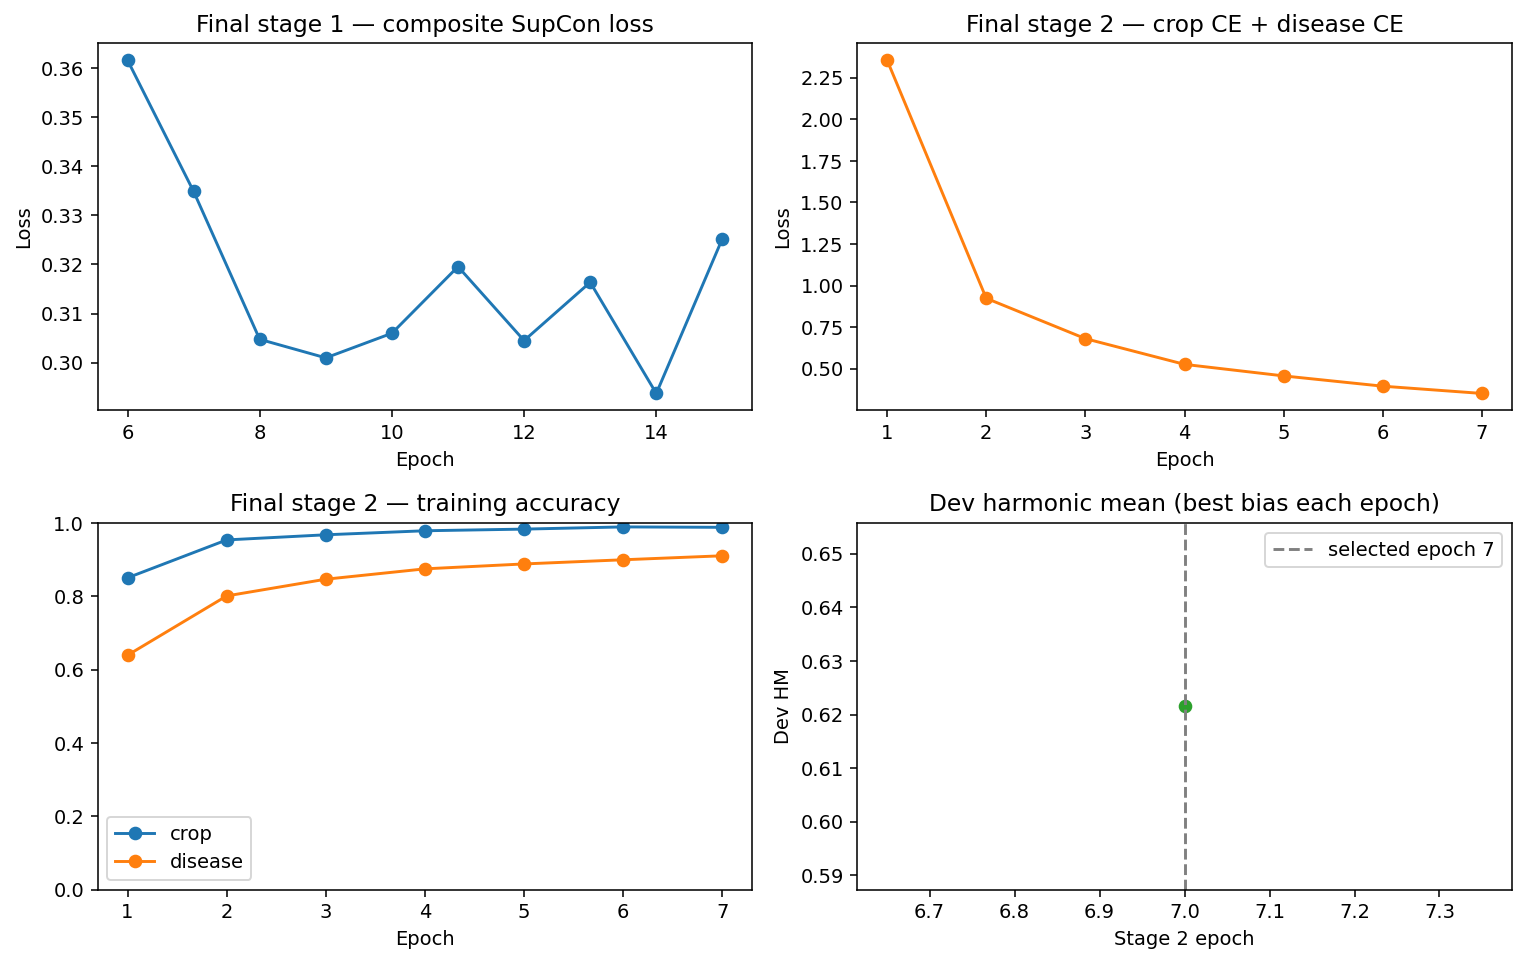

### Test bias sweep

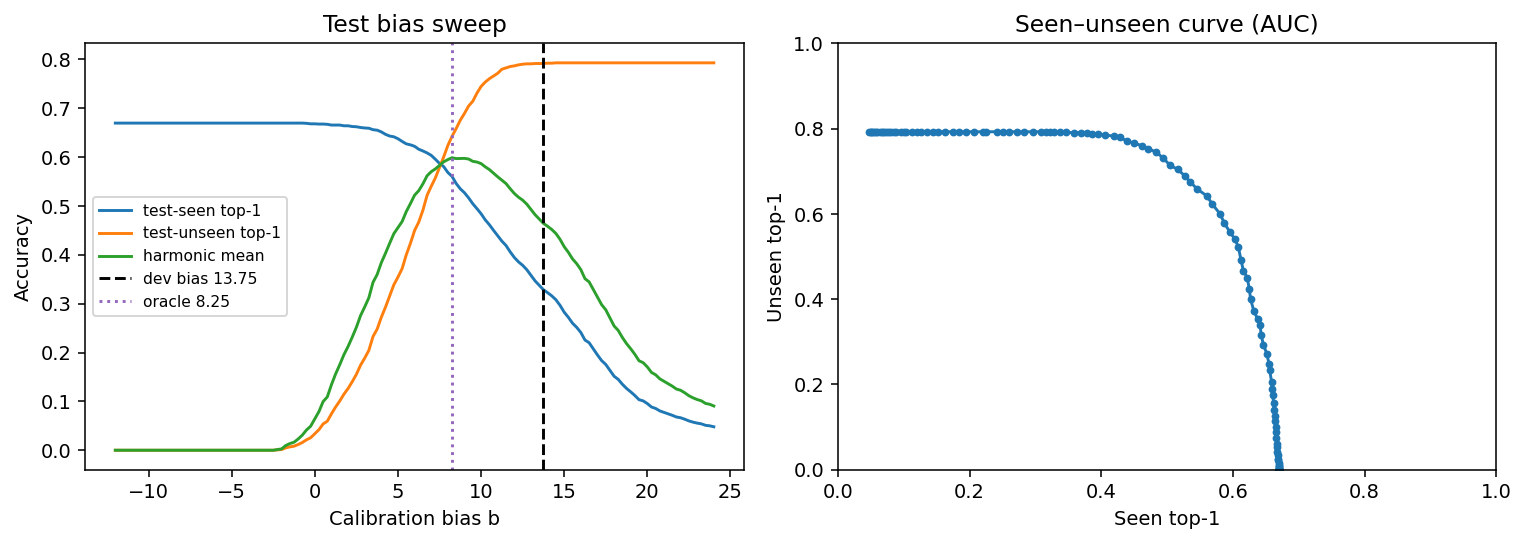

### Comparison with Baseline 2

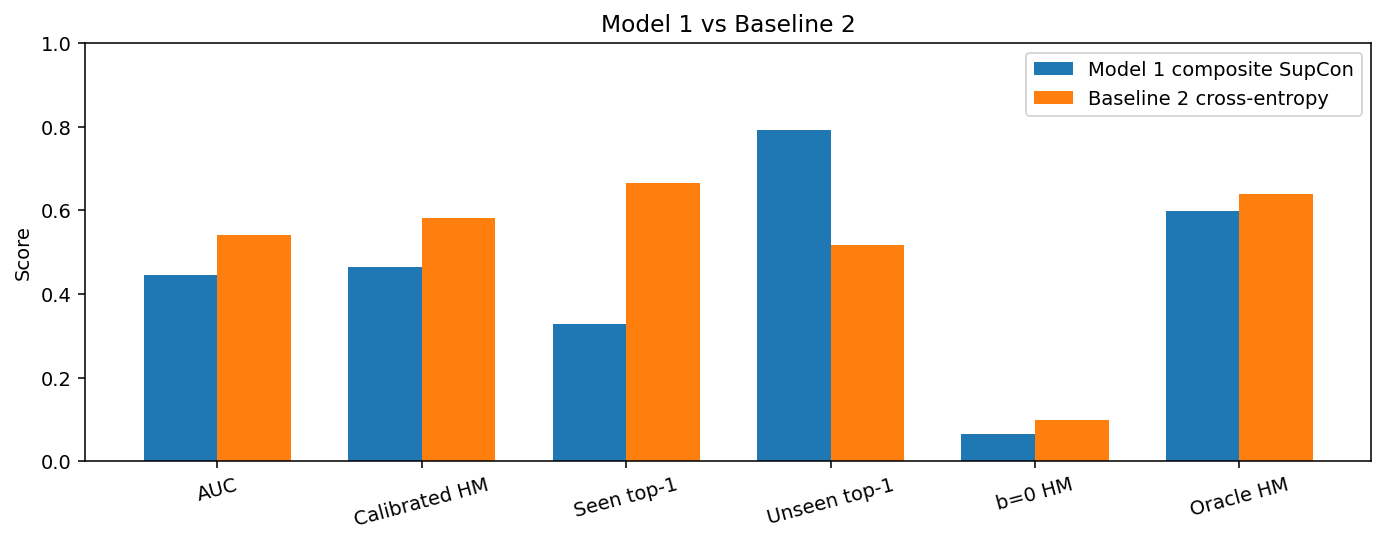

### Unseen confusions

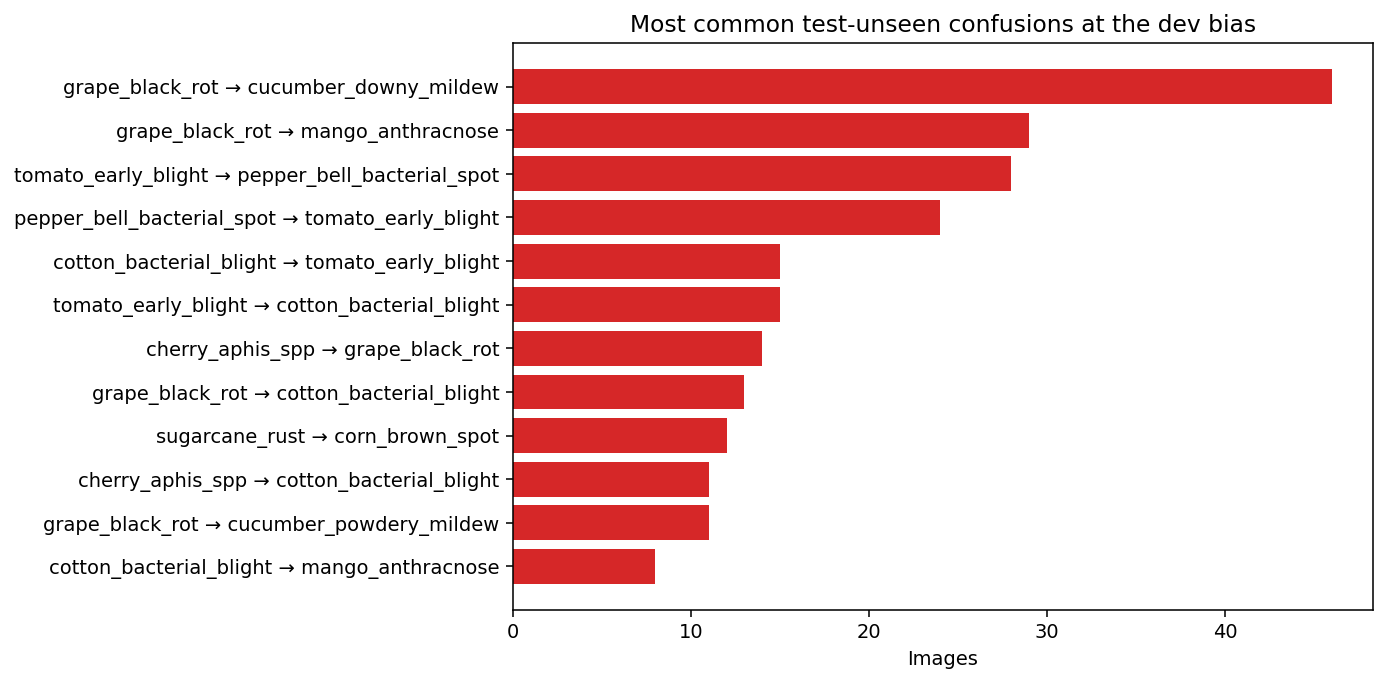

### CLS token t-SNE

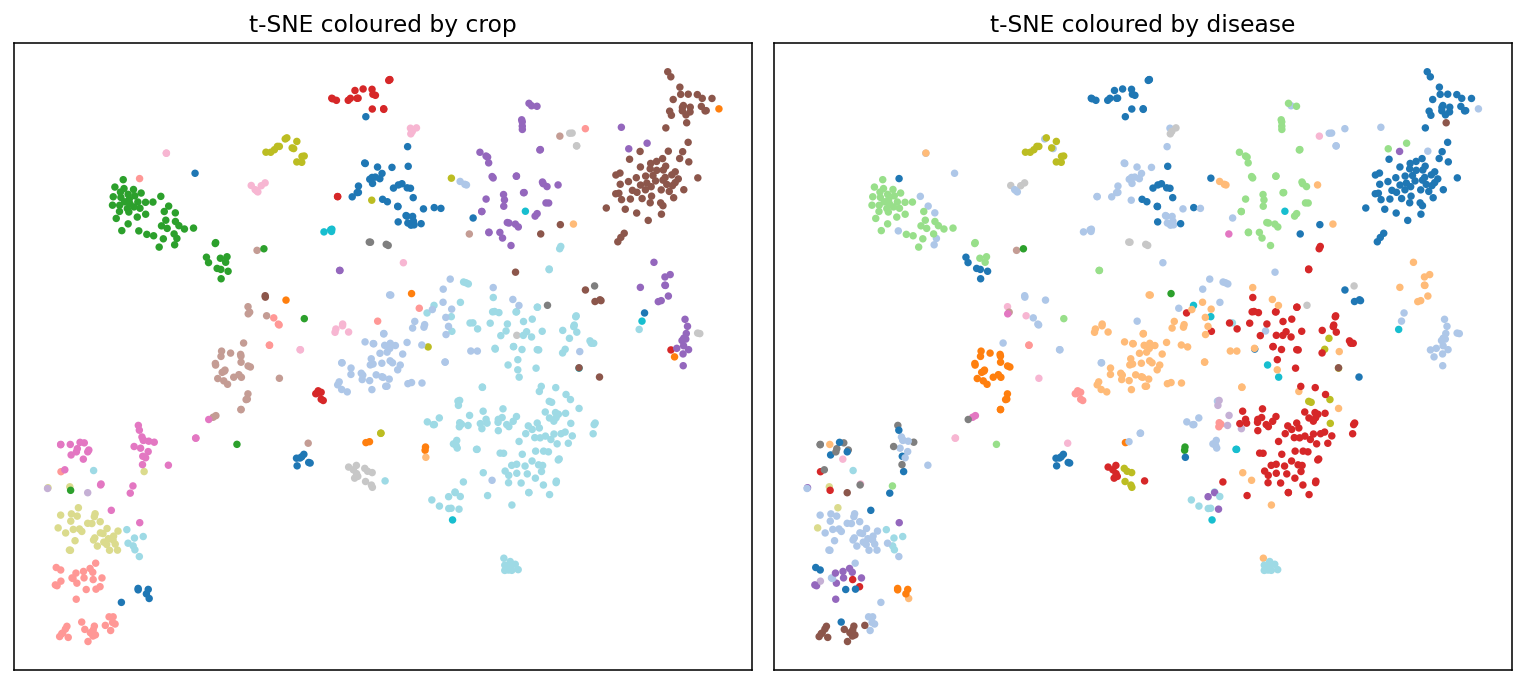

### Predictions on test images

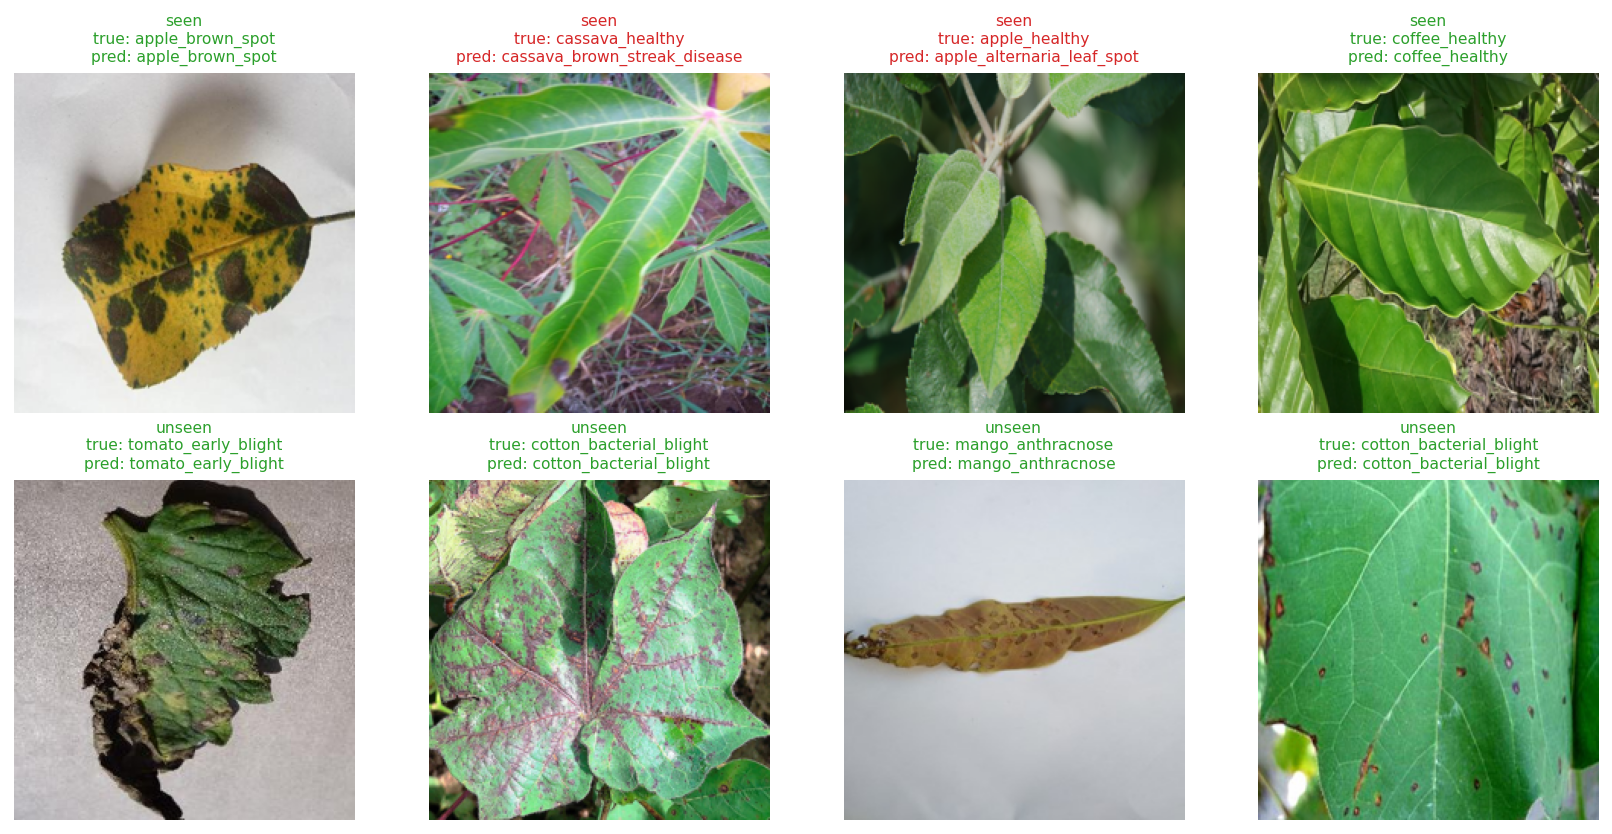

Checkpoint: /content/drive/MyDrive/deep_learning/model1_results/best.pt
Metrics: /content/drive/MyDrive/deep_learning/model1_results/metrics.json


In [ ]:
import json
from IPython.display import Image as DisplayImage, Markdown, display

if RUN_TRAINING:
    metrics = train_and_evaluate(CFG)
    out = Path(metrics["artifacts"]["output_dir"])
else:
    out = Path(CFG["output_dir"])
    metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))

table = comparison_table(metrics)
display(Markdown("### Test metrics"))
display(table.round(4))

reported = metrics["results"]["b from dev validation (REPORTED)"]
base = metrics["baseline2"]["results"]["b from dev validation (REPORTED)"]
display(Markdown(
    f"Model 1 uses dev bias **{float(metrics['dev_bias']):.2f}** after "
    f"**{metrics['epochs']['stage1']}** contrastive epochs and "
    f"**{metrics['epochs']['stage2']}** linear-probe epochs. "
    f"Calibrated harmonic mean is **{reported['harmonic mean']:.4f}** "
    f"(seen top-1 {reported['seen top-1']:.4f}, unseen top-1 {reported['unseen top-1']:.4f}). "
    f"Baseline 2 calibrated harmonic mean is **{base['harmonic mean']:.4f}**. "
    f"AUC is **{metrics['auc']:.4f}** versus Baseline 2 **{metrics['baseline2']['auc']:.4f}**."
))

figures = [
    ("Training curves", "training_curves.png"),
    ("Test bias sweep", "bias_curve.png"),
    ("Comparison with Baseline 2", "comparison_bars.png"),
    ("Unseen confusions", "top_confusions.png"),
    ("CLS token t-SNE", "tsne_crop_vs_disease.png"),
    ("Predictions on test images", "qualitative_predictions.png"),
]
for title, name in figures:
    path = out / name
    if path.exists():
        display(Markdown(f"### {title}"))
        display(DisplayImage(filename=str(path)))

print("Checkpoint:", out / "best.pt")
print("Metrics:", out / "metrics.json")


In [5]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Markdown, display

out = Path("/content/drive/MyDrive/deep_learning/model1_results")
metrics = json.loads((out / "metrics.json").read_text(encoding="utf-8"))

def show_best_model(metrics):
    key = "b from dev validation (REPORTED)"
    candidates = {
        "Model 1 (Composite SupCon, ViT-B/16)": (metrics["results"][key], metrics["auc"]),
        "Baseline 2 (multi-task ResNet-50)": (
            metrics["baseline2"]["results"][key],
            metrics["baseline2"].get("auc"),
        ),
    }
    best_name = max(candidates, key=lambda n: candidates[n][0]["harmonic mean"])
    rows = []
    for name, (res, auc_) in candidates.items():
        rows.append({
            "Model": ("★ " if name == best_name else "") + name,
            "Harmonic mean": res["harmonic mean"],
            "Seen top-1": res["seen top-1"],
            "Unseen top-1": res["unseen top-1"],
            "Seen top-5": res["seen top-5"],
            "Unseen top-5": res["unseen top-5"],
            "AUC": auc_,
        })
    frame = pd.DataFrame(rows).sort_values("Harmonic mean", ascending=False)
    best = candidates[best_name][0]
    display(Markdown(
        f"## Best model accuracy\n"
        f"**{best_name}** — harmonic mean **{best['harmonic mean']:.2%}**, "
        f"seen top-1 **{best['seen top-1']:.2%}**, unseen top-1 **{best['unseen top-1']:.2%}** "
        f"(top-5: seen {best['seen top-5']:.2%}, unseen {best['unseen top-5']:.2%})."
    ))
    display(frame.style.hide(axis="index").format(
        {c_: "{:.2%}" for c_ in frame.columns if c_ not in ("Model", "AUC")} | {"AUC": "{:.4f}"}
    ))

show_best_model(metrics)

## Best model accuracy
**Baseline 2 (multi-task ResNet-50)** — harmonic mean **58.06%**, seen top-1 **66.40%**, unseen top-1 **51.59%** (top-5: seen 89.90%, unseen 93.65%).

Model,Harmonic mean,Seen top-1,Unseen top-1,Seen top-5,Unseen top-5,AUC
★ Baseline 2 (multi-task ResNet-50),58.06%,66.40%,51.59%,89.90%,93.65%,0.5409
"Model 1 (Composite SupCon, ViT-B/16)",46.43%,32.85%,79.14%,75.75%,98.27%,0.4444
